# for picking best health_score and terminal models
## based on amount of advantage accumulated and how in-distribution the policy is

## the formula is: 
One thing worth flagging for the paper's methods section, since you're now using three sequential criteria: state the full selection cascade explicitly and in this order — (1) exclude own-critic advantage ≤ 0 [training-validity gate], (2) exclude alphas at/above the SARSA-advantage instability onset [reliability gate], (3) among survivors, select by highest occupancy support, breaking ties by SARSA-advantage [safety-first final pick]. That's a fully principled, three-stage, pre-specified procedure — worth writing it as a single clear paragraph or even a small flowchart/algorithm box, since a reviewer will want to see this reasoning laid out plainly rather than reconstructed from separate analyses.

In [28]:
import sys
import os
from pathlib import Path
import importlib
import json

import numpy as np
import matplotlib.pyplot as plt
import torch


# Optional but very useful in notebooks
%load_ext autoreload
%autoreload 2

repo_root = Path("/home/jake/Documents/AI_Clinician/ai_clinician_pediatric_rl")
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from src.rl.analysis import runs as R, models as M, data as D
import src.rl.evaluate_cql_alpha_sweep as eval_cql

R.set_path_mappings([
    ("/rds/general/user/jormond/home/projects/ai_clinician/dynamic_deephit_results/mimic_iv/",
     "/home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/mimic_iv/"),
    ("/rds/general/user/jormond/home/projects/ai_clinician",
     "/home/jake/Documents/AI_Clinician/models"),
])
print(R.PATH_MAPPINGS)   # should now list both pairs, longest prefix first


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
[('/rds/general/user/jormond/home/projects/ai_clinician/dynamic_deephit_results/mimic_iv', '/home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/mimic_iv'), ('/rds/general/user/jormond/home/projects/ai_clinician', '/home/jake/Documents/AI_Clinician/models')]


# get paths to the models

In [29]:
basic_q_dir = "/home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/basic_q/split_0/sepsis/combined_hourly_iv-vasoactive_inotropic_score/"
print(f"Using basic_q_dir: {basic_q_dir}")
dynamic_deephit_model_dir = "/home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/mimic_iv/split_0/sepsis/combined_hourly_iv-vasoactive_inotropic_score/"
print(f"Using dynamic_deephit_model_dir: {dynamic_deephit_model_dir}")
cql_model_dir = "/home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/cql_with_logprobs/split_0/sepsis/combined_hourly_iv-vasoactive_inotropic_score/"
print(f"Using cql_model_dir: {cql_model_dir}")

Using basic_q_dir: /home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/basic_q/split_0/sepsis/combined_hourly_iv-vasoactive_inotropic_score/
Using dynamic_deephit_model_dir: /home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/mimic_iv/split_0/sepsis/combined_hourly_iv-vasoactive_inotropic_score/
Using cql_model_dir: /home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/cql_with_logprobs/split_0/sepsis/combined_hourly_iv-vasoactive_inotropic_score/


In [30]:
cql_hs_dir      = os.path.join(cql_model_dir, "with_actions", "health_score_change_only", "alpha_sweep")
cql_term_dir    = os.path.join(cql_model_dir, "with_actions", "terminal_only", "alpha_sweep")
sarsa_hs_dir    = os.path.join(basic_q_dir, "with_actions", "health_score_change_only", "five_seeds")
sarsa_term_dir  = os.path.join(basic_q_dir, "with_actions", "terminal_only", "five_seeds")   # confirm

print(f"Using cql_hs_dir: {cql_hs_dir}")
print(f"Using cql_term_dir: {cql_term_dir}")
print(f"Using sarsa_hs_dir: {sarsa_hs_dir}")
print(f"Using sarsa_term_dir: {sarsa_term_dir}")

Using cql_hs_dir: /home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/cql_with_logprobs/split_0/sepsis/combined_hourly_iv-vasoactive_inotropic_score/with_actions/health_score_change_only/alpha_sweep
Using cql_term_dir: /home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/cql_with_logprobs/split_0/sepsis/combined_hourly_iv-vasoactive_inotropic_score/with_actions/terminal_only/alpha_sweep
Using sarsa_hs_dir: /home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/basic_q/split_0/sepsis/combined_hourly_iv-vasoactive_inotropic_score/with_actions/health_score_change_only/five_seeds
Using sarsa_term_dir: /home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/basic_q/split_0/sepsis/combined_hourly_iv-vasoactive_inotropic_score/with_actions/terminal_only/five_seeds


# load health score models

In [31]:
print(R.PATH_MAPPINGS)
print(R.map_path("/rds/general/user/jormond/home/projects/ai_clinician/dynamic_deephit_results/mimic_iv/split_0"))

[('/rds/general/user/jormond/home/projects/ai_clinician/dynamic_deephit_results/mimic_iv', '/home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/mimic_iv'), ('/rds/general/user/jormond/home/projects/ai_clinician', '/home/jake/Documents/AI_Clinician/models')]
/home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/mimic_iv/split_0


In [19]:
hs_study = R.make_study(cql_hs_dir, group_by=("cql_alpha",), name="CQL alpha sweep (health score)")
_ = hs_study.check(ignore=R.DEFAULT_IGNORE_KEYS | {"ratio_of_fluid_to_vaso"})

import pandas as pd
have = pd.crosstab([k[0] for k, s, r in hs_study.items()], [s for k, s, r in hs_study.items()])
have[(have != 1).any(axis=1)]

Study 'CQL alpha sweep (health score)': 32 group(s), 155 run(s), seeds [0, 1, 2, 3, 4]
  between groups:
      cql_alpha                                {'cql_alpha=0.0': 0.0, 'cql_alpha=0.0001': 0.0001, 'cql_alpha=0.001': 0.001, 'cql_alpha=0.005': 0.005, 'cql_alpha=0.01': 0.01, 'cql_alpha=0.015': 0.015, 'cql_alpha=0.02': 0.02, 'cql_alpha=0.021': 0.021, 'cql_alpha=0.022': 0.022, 'cql_alpha=0.023': 0.023, 'cql_alpha=0.024': 0.024, 'cql_alpha=0.025': 0.025, 'cql_alpha=0.026': 0.026, 'cql_alpha=0.027': 0.027, 'cql_alpha=0.028': 0.028, 'cql_alpha=0.029': 0.029, 'cql_alpha=0.03': 0.03, 'cql_alpha=0.0325': 0.0325, 'cql_alpha=0.035': 0.035, 'cql_alpha=0.0375': 0.0375, 'cql_alpha=0.04': 0.04, 'cql_alpha=0.0425': 0.0425, 'cql_alpha=0.045': 0.045, 'cql_alpha=0.05': 0.05, 'cql_alpha=0.055': 0.055, 'cql_alpha=0.06': 0.06, 'cql_alpha=0.065': 0.065, 'cql_alpha=0.07': 0.07, 'cql_alpha=0.075': 0.075, 'cql_alpha=0.1': 0.1, 'cql_alpha=0.5': 0.5, 'cql_alpha=1.0': 1.0}
  PROBLEMS:
    - groups have differe

col_0,0,1,2,3,4
row_0,,,,,
0.0230,0,0,0,1,0
0.0375,1,1,1,0,1


In [6]:
hs_study = R.make_study(cql_hs_dir, group_by=("cql_alpha",), name="CQL alpha sweep (health score)")
hs_study = hs_study.complete(seeds=range(5))     # drops any alpha missing a seed, and prints which
_ = hs_study.check(ignore=R.DEFAULT_IGNORE_KEYS | {"ratio_of_fluid_to_vaso"})
sarsa_hs_study = R.make_study(sarsa_hs_dir, name="SARSA (health score)")
_ = sarsa_hs_study.check(ignore=R.DEFAULT_IGNORE_KEYS | {"ratio_of_fluid_to_vaso"})

cql_hs_models = M.load_study_models(hs_study)
sarsa_hs_models = M.load_study_models(sarsa_hs_study)

  dropped cql_alpha=0.023: missing seeds [0, 1, 2, 4]
  dropped cql_alpha=0.0375: missing seeds [3]
Study 'CQL alpha sweep (health score)': kept 30 of 32 group(s) with seeds [0, 1, 2, 3, 4]
Study 'CQL alpha sweep (health score)': 30 group(s), 150 run(s), seeds [0, 1, 2, 3, 4]
  between groups:
      cql_alpha                                {'cql_alpha=0.0': 0.0, 'cql_alpha=0.0001': 0.0001, 'cql_alpha=0.001': 0.001, 'cql_alpha=0.005': 0.005, 'cql_alpha=0.01': 0.01, 'cql_alpha=0.015': 0.015, 'cql_alpha=0.02': 0.02, 'cql_alpha=0.021': 0.021, 'cql_alpha=0.022': 0.022, 'cql_alpha=0.024': 0.024, 'cql_alpha=0.025': 0.025, 'cql_alpha=0.026': 0.026, 'cql_alpha=0.027': 0.027, 'cql_alpha=0.028': 0.028, 'cql_alpha=0.029': 0.029, 'cql_alpha=0.03': 0.03, 'cql_alpha=0.0325': 0.0325, 'cql_alpha=0.035': 0.035, 'cql_alpha=0.04': 0.04, 'cql_alpha=0.0425': 0.0425, 'cql_alpha=0.045': 0.045, 'cql_alpha=0.05': 0.05, 'cql_alpha=0.055': 0.055, 'cql_alpha=0.06': 0.06, 'cql_alpha=0.065': 0.065, 'cql_alpha=0.07':

# load data

In [7]:
print(len(hs_study.data_identities()), "CQL identities (expect 5);",
      {v.short() for v in sarsa_hs_study.data_identities().values()} <=
      {v.short() for v in hs_study.data_identities().values()}, "(SARSA shares them)")

store = D.DataStore(keep=("train", "val"))
paired = store.pair({k: v for k, v in cql_hs_models.items() if k == (0.03,)}, split="val")
display(D.check_rows_aligned({s: p for s, (m, p) in paired[(0.03,)].items()}))

5 CQL identities (expect 5); True (SARSA shares them)
  building processors for state seed 0, shared reward [mimic_iv_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20261030_002923_675400_job4502770.pbs-7]  (splits: train, val)
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
  building processors for state seed 1, shared reward [mimic_iv_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20261030_002923_675400_job4502770.pbs-7]  (splits: train, val)
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
  building processors for state seed 2, shared reward [mimic_iv_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20261030_0029

,n_rows,same_index_ptr,same_actions,same_health_score,same_rewards,same_states
0,174053,True,True,True,True,True
1,174053,True,True,True,True,False
2,174053,True,True,True,True,False
3,174053,True,True,True,True,False
4,174053,True,True,True,True,False


# run sweep

In [8]:
df_hs = eval_cql.run_alpha_sweep_analysis(cql_hs_models, sarsa_hs_models, store, n_severity_bins=200)
display(eval_cql.summarize_by_alpha(df_hs))

alpha=0          (deterministic, val, 5 seeds)  own_norm=+0.0631  sarsa_norm=+0.5318 [+0.4078, +0.7819]  occupancy=71.7%  (3.4s)
alpha=0.0001     (deterministic, val, 5 seeds)  own_norm=+0.0623  sarsa_norm=+0.5315 [+0.4075, +0.7773]  occupancy=71.8%  (2.0s)
alpha=0.001      (deterministic, val, 5 seeds)  own_norm=+0.0522  sarsa_norm=+0.5323 [+0.4182, +0.7692]  occupancy=72.7%  (2.1s)
alpha=0.005      (deterministic, val, 5 seeds)  own_norm=+0.0210  sarsa_norm=+0.4677 [+0.4100, +0.6128]  occupancy=84.3%  (2.1s)
alpha=0.01       (deterministic, val, 5 seeds)  own_norm=+0.0098  sarsa_norm=+0.3829 [+0.3384, +0.4461]  occupancy=89.3%  (2.1s)
alpha=0.015      (deterministic, val, 5 seeds)  own_norm=+0.0076  sarsa_norm=+0.2734 [+0.2095, +0.3307]  occupancy=90.7%  (2.0s)
alpha=0.02       (deterministic, val, 5 seeds)  own_norm=+0.0071  sarsa_norm=+0.2060 [+0.1649, +0.2352]  occupancy=92.2%  (2.0s)
alpha=0.021      (deterministic, val, 5 seeds)  own_norm=+0.0072  sarsa_norm=+0.2001 [+0.1657, +0

own_adv                               own_adv_norm            \
            mean       min       max       std         mean       min   
alpha                                                                   
0.0000  0.101973  0.098717  0.105735  0.002671     0.063123  0.051895   
0.0001  0.100373  0.096756  0.106326  0.003811     0.062329  0.051991   
0.0010  0.085708  0.082584  0.088505  0.002232     0.052158  0.042449   
0.0050  0.050012  0.045249  0.055370  0.004073     0.021038  0.016983   
0.0100  0.034288  0.030804  0.040100  0.003805     0.009780  0.007556   
0.0150  0.032548  0.024746  0.036911  0.004732     0.007620  0.005953   
0.0200  0.032708  0.030340  0.034715  0.001842     0.007125  0.006021   
0.0210  0.032712  0.029998  0.035254  0.002209     0.007159  0.006083   
0.0220  0.032622  0.029804  0.035207  0.002349     0.007179  0.005936   
0.0240  0.032462  0.028514  0.035229  0.002722     0.006996  0.005680   
0.0250  0.032593  0.029143  0.035207  0.002542     0.006916  0.005524   
0.0260  0.033105  0.030282  0.035766  0.002004     0.006886  0.005638   
0.0270  0.033101  0.029834  0.035396  0.002086     0.006782  0.005392   
0.0280  0.033637  0.031201  0.035127  0.001487     0.006940  0.005552   
0.0290  0.033766  0.031281  0.035731  0.001624     0.006784  0.005497   
0.0300  0.033734  0.031106  0.035295  0.001624     0.006781  0.005578   
0.0325  0.034481  0.032446  0.035593  0.001271     0.006736  0.005653   
0.0350  0.035199  0.033490  0.036776  0.001236     0.006894  0.005961   
0.0400  0.035960  0.034797  0.037057  0.000883     0.007019  0.006238   
0.0425  0.036030  0.034411  0.037699  0.001399     0.007419  0.006262   
0.0450  0.036457  0.034394  0.037895  0.001299     0.007324  0.006416   
0.0500  0.035614  0.033039  0.039601  0.002506     0.007569  0.006202   
0.0550  0.036099  0.033925  0.038371  0.001878     0.007783  0.006539   
0.0600  0.035323  0.031595  0.039188  0.002834     0.007411  0.006816   
0.0650  0.036469  0.033158  0.040941  0.003135     0.007441  0.006494   
0.0700  0.036898  0.032553  0.042729  0.003686     0.007183  0.005959   
0.0750  0.038362  0.034151  0.043960  0.004399     0.007718  0.006613   
0.1000  0.038332  0.032990  0.045138  0.004592     0.006200  0.005709   
0.5000 -0.100149 -0.126235 -0.088678  0.015850    -0.021931 -0.031087   
1.0000 -0.200050 -0.211546 -0.179988  0.012777    -0.047908 -0.060514   

                           sarsa_adv            ...           sarsa_adv_norm  \
             max       std      mean       min  ...       std           mean   
alpha                                           ...                            
0.0000  0.070088  0.007559  0.328313  0.268596  ...  0.080368       0.531798   
0.0001  0.070285  0.007900  0.328266  0.268378  ...  0.079176       0.531505   
0.0010  0.057495  0.006453  0.328797  0.275487  ...  0.075617       0.532279   
0.0050  0.023772  0.003562  0.290328  0.241216  ...  0.047327       0.467734   
0.0100  0.012179  0.001873  0.238346  0.199813  ...  0.027187       0.382928   
0.0150  0.009056  0.001427  0.171448  0.124451  ...  0.040220       0.273447   
0.0200  0.007958  0.000787  0.128476  0.103082  ...  0.020033       0.205969   
0.0210  0.007908  0.000668  0.125032  0.098344  ...  0.019327       0.200137   
0.0220  0.008241  0.000846  0.120997  0.096279  ...  0.018273       0.193770   
0.0240  0.007922  0.000902  0.114331  0.088792  ...  0.018638       0.182809   
0.0250  0.007743  0.001008  0.110935  0.086030  ...  0.017699       0.177320   
0.0260  0.007693  0.000845  0.109718  0.083606  ...  0.019053       0.175240   
0.0270  0.008128  0.001180  0.107792  0.082359  ...  0.018730       0.172123   
0.0280  0.008347  0.001041  0.105868  0.080567  ...  0.018643       0.169023   
0.0290  0.007982  0.000978  0.104384  0.080595  ...  0.017642       0.166727   
0.0300  0.008221  0.001004  0.102923  0.077658  ...  0.017892       0.164252   
0.0325  0.007886  0.000883  0.098180  0.073944  ...  0.016266       0.156638   

Note: alpha=0 excluded from plot (log scale can't show it).
Saved to /home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/cql_with_logprobs/split_0/sepsis/combined_hourly_iv-vasoactive_inotropic_score/cql_alpha_sweep_health_score.png
Note: alpha=0 excluded from plot (log scale can't show it).
Saved to /home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/cql_with_logprobs/split_0/sepsis/combined_hourly_iv-vasoactive_inotropic_score/cql_alpha_sweep_combined_health_score.png


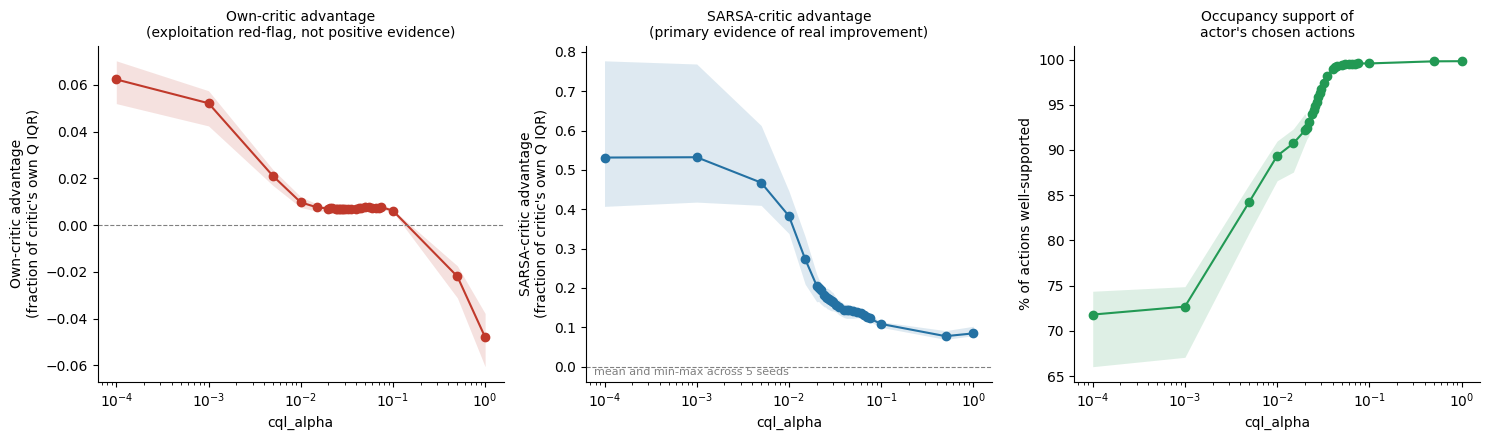

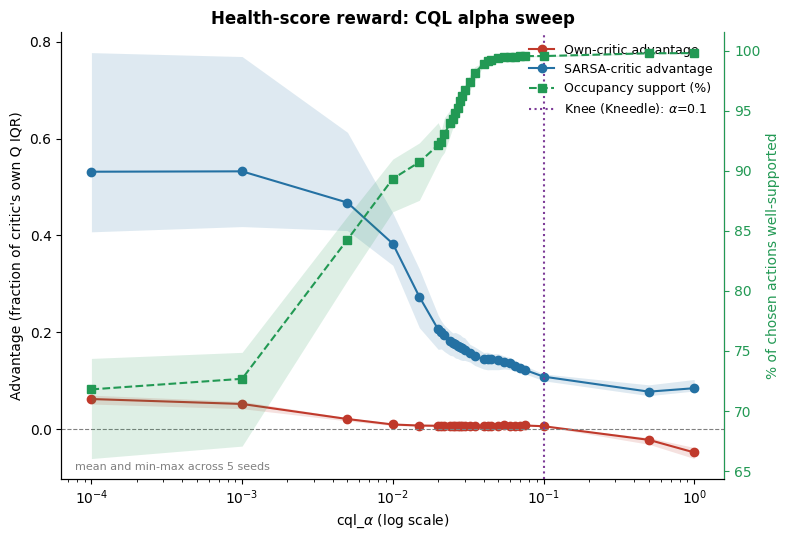

In [9]:
fig = eval_cql.plot_alpha_sweep(df_hs, normalized=True, log_scale=True,
        save_path=os.path.join(cql_model_dir, "cql_alpha_sweep_health_score.png"))
fig = eval_cql.plot_combined_alpha_sweep(df_hs, normalized=True, log_scale=True,
        title="Health-score reward: CQL alpha sweep",
        save_path=os.path.join(cql_model_dir, "cql_alpha_sweep_combined_health_score.png"))

,mean,std,n_seeds,n_seeds_positive,cv,worst_window_ratio,unstable
alpha,,,,,,,
0.0000,0.531798,0.149328,5,5,0.280799,1.001456,False
0.0001,0.531505,0.146690,5,5,0.275991,1.137995,False
0.0010,0.532279,0.141292,5,5,0.265448,1.390022,False
0.0050,0.467734,0.084473,5,5,0.180600,1.710513,False
0.0100,0.382928,0.040428,5,5,0.105576,1.859152,False
0.0150,0.273447,0.050569,5,5,0.184933,1.859152,False
0.0200,0.205969,0.026545,5,5,0.128877,1.859152,False
0.0210,0.200137,0.022690,5,5,0.113370,1.366294,False
0.0220,0.193770,0.021810,5,5,0.112557,1.094788,False


instability onset: None


max_ratio,1.25,1.50,2.00,3.00,5.00
window,,,,,
3,0.0010,0.0050,NaN,NaN,NaN
4,0.0001,0.0010,0.005,NaN,NaN
5,0.0000,0.0001,0.001,NaN,NaN


Note: alpha=0 excluded from plot (log scale can't show it).
Saved to /home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/cql_with_logprobs/split_0/sepsis/combined_hourly_iv-vasoactive_inotropic_score/sarsa_stability_health_score.png


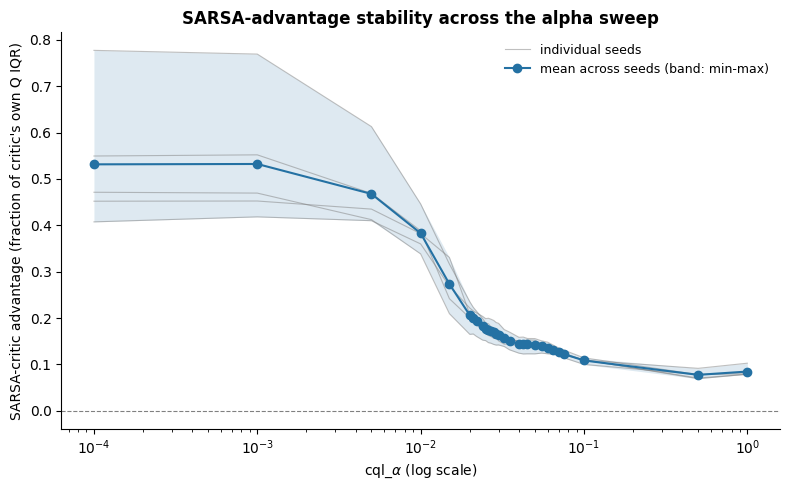

In [10]:
tab, onset = eval_cql.sarsa_stability(df_hs, window=3, max_ratio=2.0)
display(tab)
print("instability onset:", onset)
display(eval_cql.stability_sensitivity(df_hs))      # onset alpha across windows and thresholds

fig = eval_cql.plot_sarsa_stability(df_hs, onset, normalized=True, log_scale=True,
        save_path=os.path.join(cql_model_dir, "sarsa_stability_health_score.png"))

In [11]:
final_alpha, sel_info = eval_cql.select_final_alpha(df_hs, own_rule="any_seed", occupancy_margin=0.005)
display(sel_info)

alphas: 30
1. own-critic gate (any_seed): 28 pass; dropped [0.5, 1.0]
2. SARSA stability gate (window=3, max_ratio=2.0): onset=None; 28 survive both gates
3. occupancy: best survivor 99.57%, margin 0.50 points -> 9 tied: [0.0425, 0.045, 0.05, 0.055, 0.06, 0.065, 0.07, 0.075, 0.1]
4. highest SARSA advantage among the tied: alpha=0.0425 (SARSA adv 0.1444, occupancy 99.14%)


,own_adv_mean,own_adv_min,pass_own,pass_stability,sarsa_adv,occupancy,survivor,tied_occupancy,selected
alpha,,,,,,,,,
0.0000,0.063123,0.051895,True,True,0.531798,0.717435,True,False,False
0.0001,0.062329,0.051991,True,True,0.531505,0.718022,True,False,False
0.0010,0.052158,0.042449,True,True,0.532279,0.726849,True,False,False
0.0050,0.021038,0.016983,True,True,0.467734,0.842800,True,False,False
0.0100,0.009780,0.007556,True,True,0.382928,0.893484,True,False,False
0.0150,0.007620,0.005953,True,True,0.273447,0.907339,True,False,False
0.0200,0.007125,0.006021,True,True,0.205969,0.921573,True,False,False
0.0210,0.007159,0.006083,True,True,0.200137,0.924433,True,False,False
0.0220,0.007179,0.005936,True,True,0.193770,0.930806,True,False,False


# Action distributions

Saved to /home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/cql_with_logprobs/split_0/sepsis/combined_hourly_iv-vasoactive_inotropic_score/dose_histogram_fluid_health_score.png
Saved to /home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/cql_with_logprobs/split_0/sepsis/combined_hourly_iv-vasoactive_inotropic_score/fluid_at_clinician_zero_health_score.png
Saved to /home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/cql_with_logprobs/split_0/sepsis/combined_hourly_iv-vasoactive_inotropic_score/dose_histogram_vaso_health_score.png
Saved to /home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/cql_with_logprobs/split_0/sepsis/combined_hourly_iv-vasoactive_inotropic_score/vaso_at_clinician_zero_health_score.png


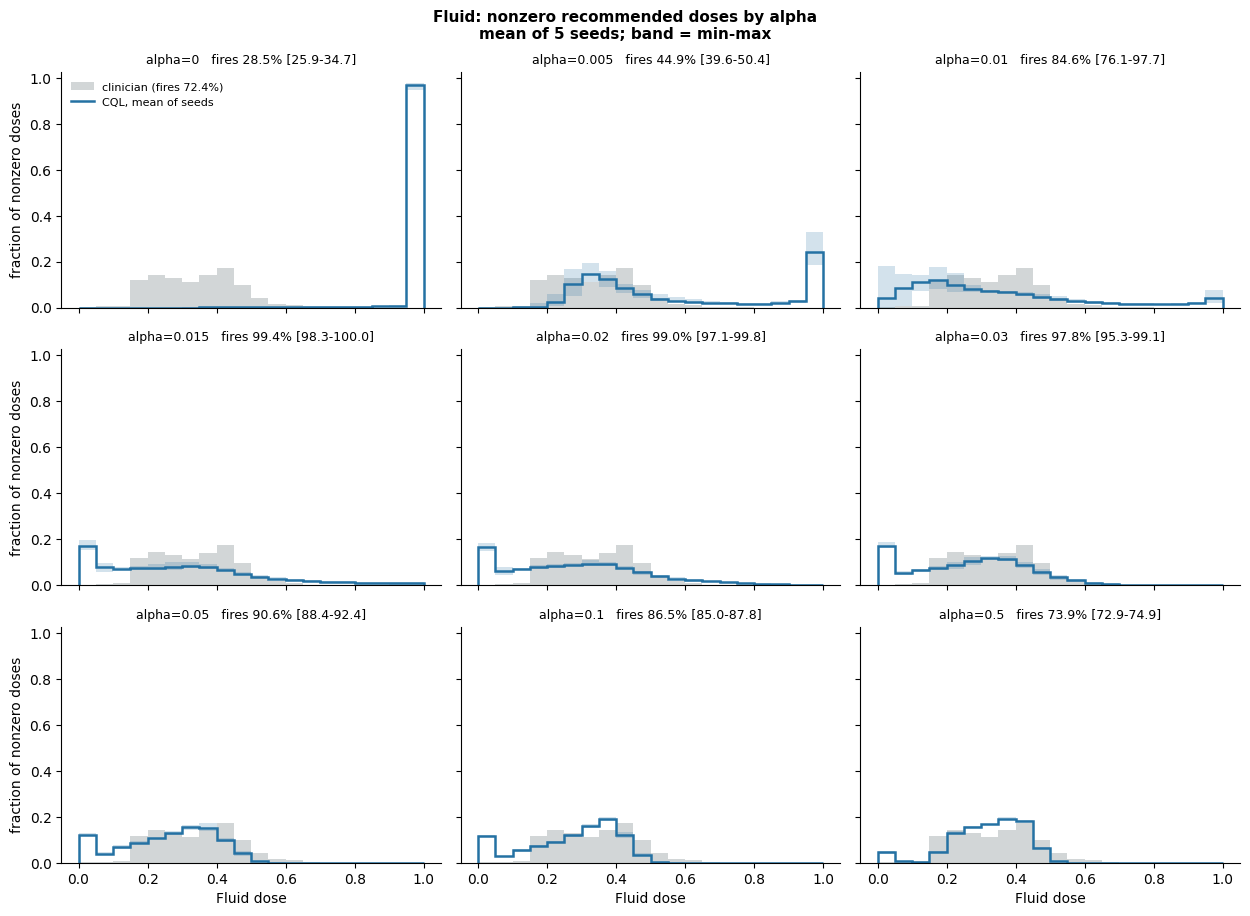

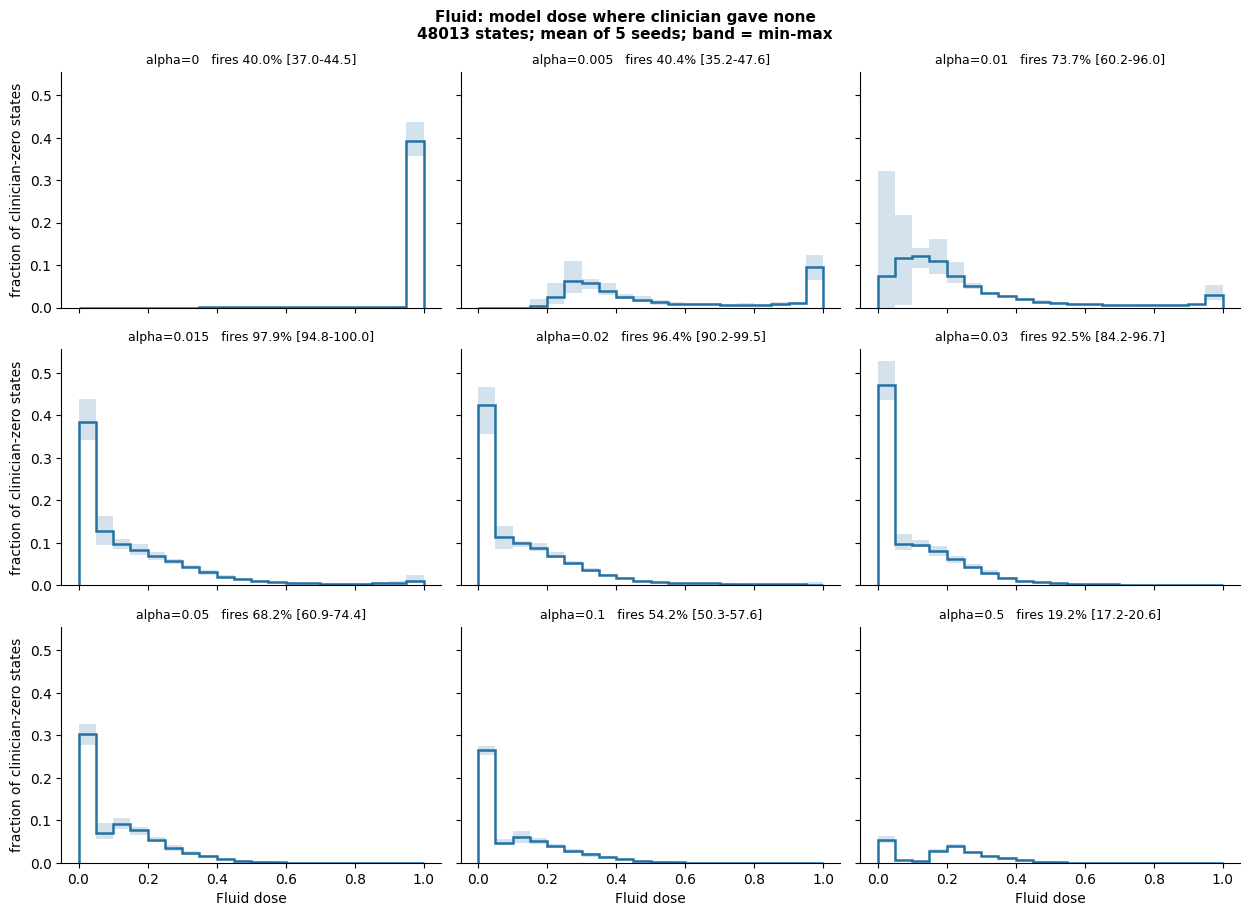

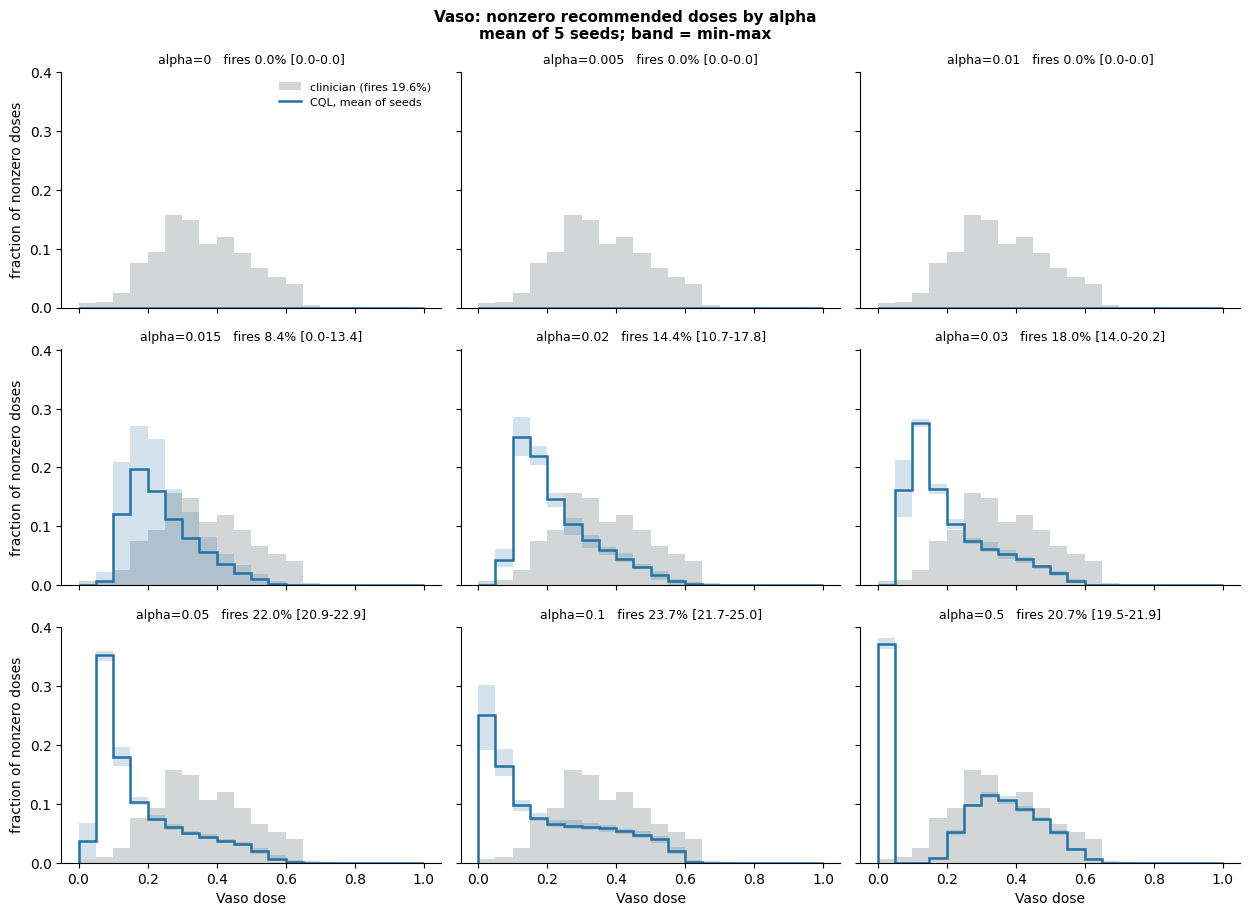

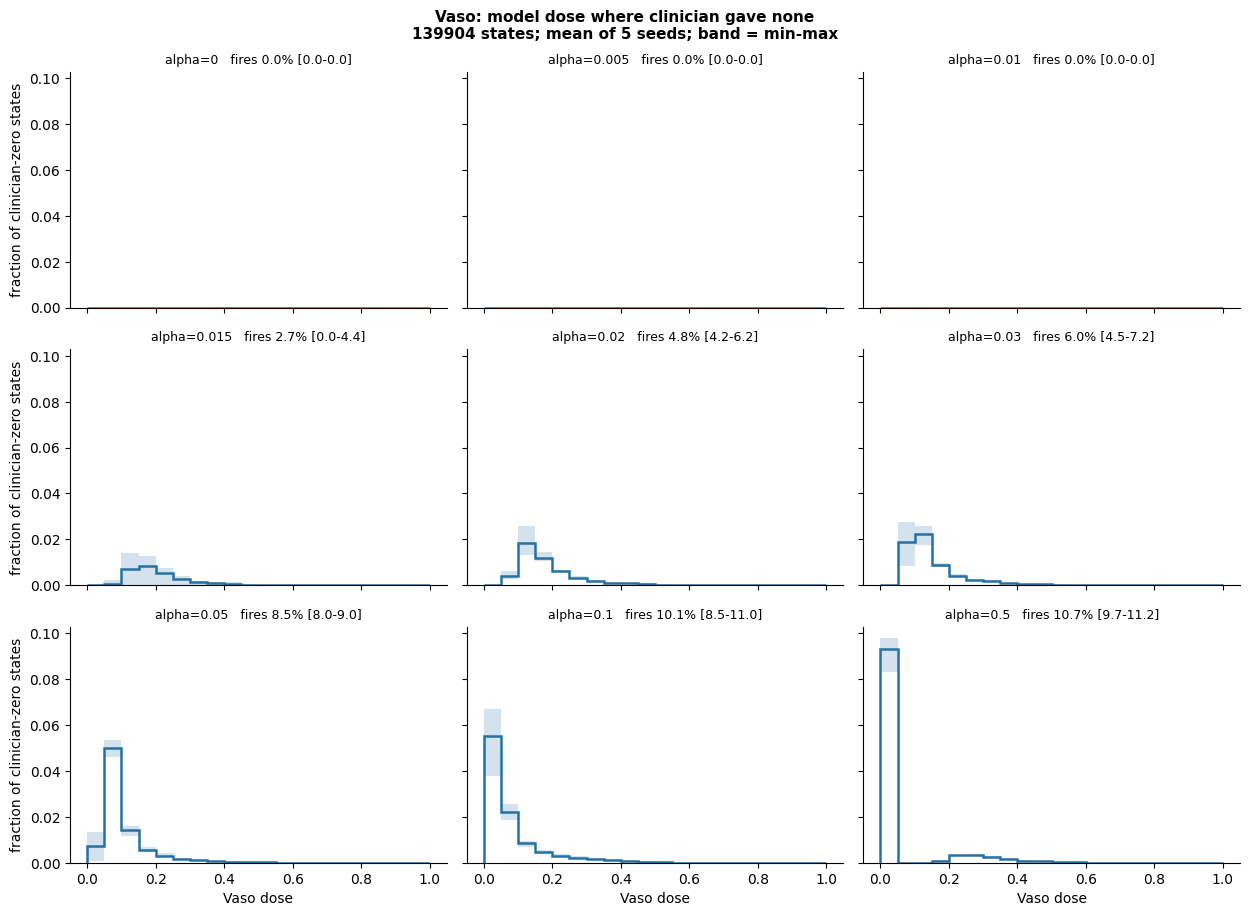

In [12]:
import src.rl.dose_histogram_by_alpha as dose_hist

actions_hs, clin_val = dose_hist.collect_actions(cql_hs_models, store, split="val")   # once; reused by all plots

show = [0, 0.005, 0.01, 0.015, 0.02, 0.03, 0.05, 0.1, 0.5]
for dim, name in [(0, "Fluid"), (1, "Vaso")]:
    dose_hist.plot_dose_histograms(actions_hs, clin_val, dim=dim, dim_name=name, alphas_to_show=show,
        save_path=os.path.join(cql_model_dir, f"dose_histogram_{name.lower()}_health_score.png"))
    dose_hist.plot_dose_histograms_at_clinician_zero(actions_hs, clin_val, dim=dim, dim_name=name, alphas_to_show=show,
        save_path=os.path.join(cql_model_dir, f"{name.lower()}_at_clinician_zero_health_score.png"))

Fluid {'fire_rate': 0.7241472425065928, 'w1': 0.0, 'low_share': 0.0019438273563947954, 'high_share': 0.0, 'median_nz': 0.3404560089111328}


fire_rate                            w1                     low_share  \
            mean       min       max      mean       min       max      mean   
alpha                                                                          
0.0000  0.284693  0.259025  0.347429  0.656366  0.650436  0.658543  0.000000   
0.0001  0.284434  0.260421  0.341551  0.655464  0.648219  0.657890  0.000000   
0.0010  0.284297  0.266970  0.337265  0.634128  0.598497  0.648879  0.000000   
0.0050  0.449143  0.395891  0.504237  0.246741  0.183437  0.305220  0.000000   
0.0100  0.845657  0.761119  0.976869  0.109590  0.090710  0.132719  0.041024   
0.0150  0.993547  0.982517  0.999845  0.105663  0.097380  0.117424  0.171204   
0.0200  0.989509  0.971089  0.998477  0.089589  0.076944  0.095937  0.166374   
0.0210  0.986963  0.980408  0.997868  0.088107  0.082997  0.090741  0.163087   
0.0220  0.987438  0.976007  0.999931  0.085257  0.076037  0.091890  0.166567   
0.0240  0.985965  0.981362  0.987837  0.082344  0.075837  0.091185  0.167766   
0.0250  0.982195  0.974875  0.986596  0.080124  0.072827  0.086409  0.166252   
0.0260  0.983674  0.979966  0.987711  0.079474  0.070845  0.087097  0.169688   
0.0270  0.984224  0.970561  0.991836  0.078957  0.068269  0.092313  0.171335   
0.0280  0.979502  0.963534  0.986292  0.077431  0.067827  0.091341  0.168581   
0.0290  0.977008  0.964045  0.991606  0.077182  0.070279  0.089757  0.168686   
0.0300  0.978330  0.953089  0.990698  0.077536  0.073206  0.089395  0.170802   
0.0325  0.958552  0.933124  0.982316  0.072061  0.061083  0.084733  0.153694   
0.0350  0.942799  0.921013  0.953899  0.071195  0.064737  0.080089  0.140294   
0.0400  0.928272  0.911131  0.949636  0.073500  0.067269  0.082304  0.134340   
0.0425  0.921519  0.898175  0.946022  0.075348  0.071143  0.085284  0.130860   
0.0450  0.912005  0.893613  0.928321  0.075360  0.070197  0.081846  0.126198   
0.0500  0.906418  0.884173  0.924259  0.078321  0.075810  0.083906  0.122239   
0.0550  0.899920  0.881502  0.922294  0.078694  0.076315  0.084977  0.120742   
0.0600  0.893593  0.874481  0.908947  0.077019  0.075093  0.079455  0.118792   
0.0650  0.889436  0.871258  0.904167  0.074635  0.072376  0.075974  0.118694   
0.0700  0.884524  0.867288  0.903121  0.073602  0.071838  0.074967  0.117659   
0.0750  0.883723  0.871131  0.896307  0.073921  0.073123  0.075005  0.120501   
0.1000  0.864883  0.849540  0.877968  0.064964  0.062294  0.067681  0.117604   
0.5000  0.738737  0.729163  0.748617  0.028447  0.027815  0.028894  0.045075   
1.0000  0.724634  0.716437  0.736293  0.028679  0.027032  0.032611  0.046809   

                           high_share                     median_nz            \
             min       max       mean       min       max      mean       min   
alpha                                                                           
0.0000  0.000000  0.000000   0.977202  0.959748  0.983447  0.999998  0.999994   
0.0001  0.000000  0.000000   0.974493  0.952343  0.981715  0.999997  0.999990   
0.0010  0.000000  0.000000   0.920702  0.827504  0.959632  0.999919  0.999696   
0.0050  0.000000  0.000000   0.269880  0.212329  0.358155  0.466337  0.379451   
0.0100  0.000000  0.182348   0.059826  0.034689  0.101905  0.278064  0.216166   
0.0150  0.151036  0.195658   0.017060  0.003006  0.028898  0.270207  0.258781   
0.0200  0.146786  0.182009   0.002925  0.000087  0.006477  0.274718  0.267827   
0.0210  0.137601  0.175794   0.002107  0.000023  0.004802  0.273234  0.265953   
0.0220  0.150277  0.183953   0.001058  0.000041  0.002556  0.274207  0.265184   
0.0240  0.138590  0.199457   0.000306  0.000000  0.000774  0.273791  0.263224   
0.0250  0.137433  0.197152   0.000070  0.000000  0.000285  0.275369  0.258212   
0.0260  0.145728  0.196856   0.000020  0.000000  0.000082  0.276076  0.262218   
0.0270  0.161291  0.197177   0.000006  0.000000  0.000029  0.277009  0.254867   
0.0280  0.150907  0.196256   0.000003  0.000000  0.000017  0.277011  0

Vaso {'fire_rate': 0.1961988589682453, 'w1': 0.0, 'low_share': 0.007145157984128379, 'high_share': 2.928343436118188e-05, 'median_nz': 0.3447365462779999}


fire_rate                            w1                     low_share  \
            mean       min       max      mean       min       max      mean   
alpha                                                                          
0.0000  0.000000  0.000000  0.000000       NaN       NaN       NaN       NaN   
0.0001  0.000000  0.000000  0.000000       NaN       NaN       NaN       NaN   
0.0010  0.000000  0.000000  0.000000       NaN       NaN       NaN       NaN   
0.0050  0.000000  0.000000  0.000000       NaN       NaN       NaN       NaN   
0.0100  0.000000  0.000000  0.000000       NaN       NaN       NaN       NaN   
0.0150  0.083804  0.000000  0.134028  0.115257  0.103665  0.127036  0.000000   
0.0200  0.144495  0.106870  0.178423  0.129767  0.119359  0.139247  0.000000   
0.0210  0.148710  0.112816  0.176647  0.131296  0.123476  0.138472  0.000000   
0.0220  0.153757  0.116361  0.181669  0.132288  0.124641  0.143077  0.000000   
0.0240  0.162860  0.125513  0.185593  0.136640  0.127501  0.140198  0.000000   
0.0250  0.165127  0.130184  0.185231  0.135773  0.128433  0.140637  0.000000   
0.0260  0.166991  0.124451  0.191005  0.137131  0.120878  0.147213  0.000000   
0.0270  0.170377  0.123244  0.191419  0.139192  0.118114  0.149311  0.000000   
0.0280  0.173564  0.129868  0.199014  0.143272  0.127825  0.156057  0.000000   
0.0290  0.176004  0.139693  0.191269  0.146151  0.140794  0.154658  0.000008   
0.0300  0.180461  0.139837  0.202197  0.149125  0.139876  0.159277  0.000107   
0.0325  0.185447  0.162376  0.203944  0.152377  0.144259  0.161203  0.000043   
0.0350  0.195526  0.167598  0.210131  0.159751  0.154017  0.168227  0.000217   
0.0400  0.207382  0.182381  0.218135  0.168716  0.165000  0.173225  0.001718   
0.0425  0.213857  0.193125  0.225345  0.174175  0.172192  0.177233  0.005701   
0.0450  0.219109  0.201358  0.225747  0.178266  0.173412  0.181798  0.013306   
0.0500  0.220105  0.209051  0.229195  0.178353  0.174283  0.186140  0.036781   
0.0550  0.220996  0.206541  0.234802  0.178477  0.173040  0.188354  0.063330   
0.0600  0.227141  0.213510  0.239990  0.178830  0.173681  0.188350  0.095656   
0.0650  0.230295  0.216463  0.244173  0.175902  0.166703  0.186715  0.122859   
0.0700  0.232039  0.213659  0.243529  0.174324  0.168270  0.183876  0.157681   
0.0750  0.232490  0.218658  0.244178  0.169913  0.164495  0.177231  0.181728   
0.1000  0.237407  0.216635  0.249958  0.160296  0.146872  0.171117  0.251463   
0.5000  0.207179  0.194688  0.219088  0.120580  0.116146  0.124630  0.372687   
1.0000  0.197032  0.190160  0.205012  0.116409  0.108270  0.126610  0.372046   

                           high_share           median_nz                      
             min       max       mean  min  max      mean       min       max  
alpha                                                                          
0.0000       NaN       NaN        NaN  NaN  NaN       NaN       NaN       NaN  
0.0001       NaN       NaN        NaN  NaN  NaN       NaN       NaN       NaN  
0.0010       NaN       NaN        NaN  NaN  NaN       NaN       NaN       NaN  
0.0050       NaN       NaN        NaN  NaN  NaN       NaN       NaN       NaN  
0.0100       NaN       NaN        NaN  NaN  NaN       NaN       NaN       NaN  
0.0150  0.000000  0.000000        0.0  0.0  0.0  0.221566  0.207572  0.233936  
0.0200  0.000000  0.000000        0.0  0.0  0.0  0.196260  0.181862  0.209433  
0.0210  0.000000  0.000000        0.0  0.0  0.0  0.195548  0.185546  0.206922  
0.0220  0.000000  0.000000        0.0  0.0  0.0  0.190971  0.180498  0.198428  
0.0240  0.000000  0.000000        0.0  0.0  0.0  0.185587  0.180870  0.196939  
0.0250  0.000000  0.000000        0.0  0.0  0.0  0.185505  0.180401  0.193718  
0.0260  0.000000  0.000000        0.0  0.0  0.0  0.183491  0.172243  0.202070  
0.0270  0.000000  0.000000        0.0  0.0  0.0  0.181145  0.168368  0.205116  
0.0280  0.000000  0.000000        0.0  0.0  0.0  0.175478  0.161053  0.193967  
0.0290

Fluid fire_rate per seed


seed,0,1,2,3,4
alpha,,,,,
0.0200,0.998477,0.995260,0.994674,0.971089,0.988044
0.0210,0.997868,0.982264,0.986975,0.987297,0.980408
0.0220,0.999931,0.982086,0.993611,0.976007,0.985556
0.0240,0.987837,0.986947,0.986113,0.987567,0.981362
0.0250,0.984528,0.986073,0.978903,0.986596,0.974875
0.0260,0.984941,0.984258,0.981494,0.987711,0.979966
0.0270,0.982500,0.988630,0.991836,0.987596,0.970561
0.0280,0.981925,0.979891,0.985866,0.986292,0.963534
0.0290,0.978805,0.969854,0.991606,0.980730,0.964045


Vaso fire_rate per seed


seed,0,1,2,3,4
alpha,,,,,
0.0200,0.158728,0.139802,0.106870,0.178423,0.138653
0.0210,0.159911,0.140296,0.112816,0.176647,0.153878
0.0220,0.164576,0.150816,0.116361,0.181669,0.155361
0.0240,0.172499,0.167415,0.125513,0.185593,0.163278
0.0250,0.174027,0.165628,0.130184,0.185231,0.170563
0.0260,0.179394,0.166760,0.124451,0.191005,0.173344
0.0270,0.182151,0.174981,0.123244,0.191419,0.180089
0.0280,0.199014,0.176262,0.129868,0.181238,0.181439
0.0290,0.191269,0.177205,0.139693,0.185880,0.185972


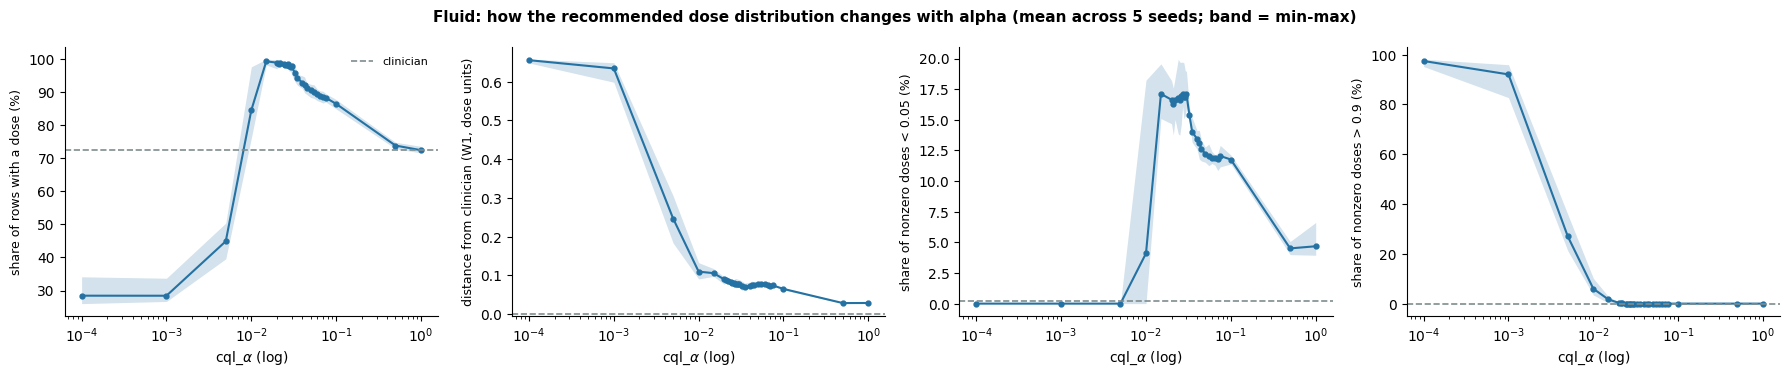

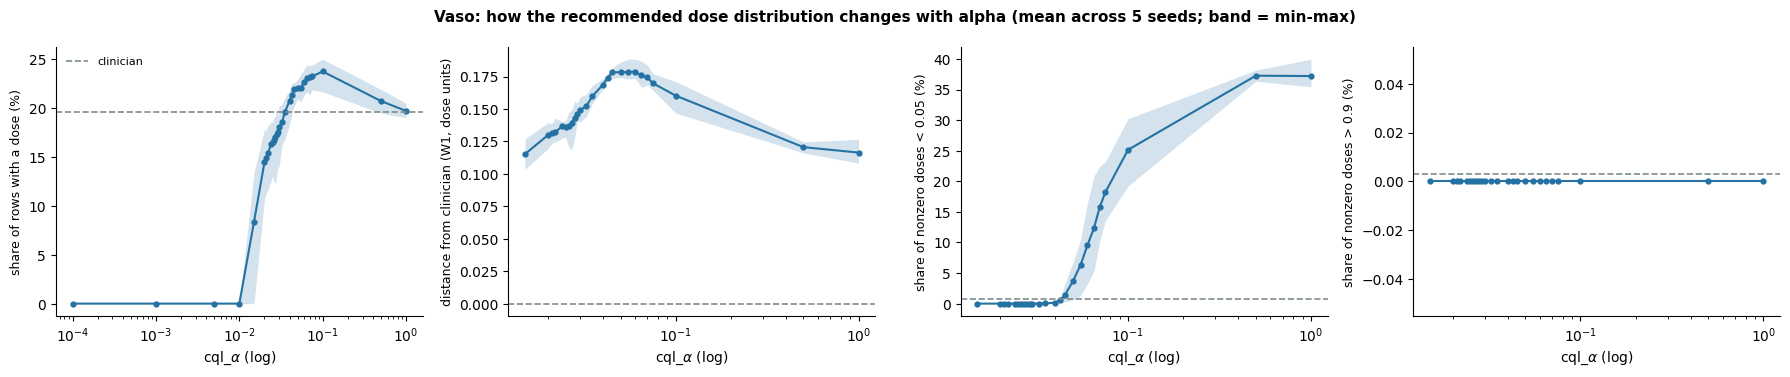

In [22]:
import importlib; importlib.reload(dose_hist)

dm = {name: dose_hist.dose_distribution_metrics(actions_hs, clin_val, dim)
      for dim, name in [(0, "Fluid"), (1, "Vaso")]}

pd.set_option("display.max_rows", None)

# Seed-averaged table at every swept alpha, plus the clinician reference
for name in dm:
    print(name, dose_hist.clinician_reference(clin_val, 0 if name == "Fluid" else 1))
    display(dose_hist.summarize_metrics(dm[name]))

# Plots unchanged
for dim, name in [(0, "Fluid"), (1, "Vaso")]:
    dose_hist.plot_dose_metrics(dm[name], clin_val, dim, name, save_path=None)

# Per-seed fire rate across the region that decides the rule (0.02-0.04)
for name in dm:
    d = dm[name][dm[name].alpha.between(0.02, 0.04)]
    print(name, "fire_rate per seed")
    display(d.pivot(index="alpha", columns="seed", values="fire_rate"))

,bin,n,fire_rate,mean_dose,median_nz,low_share,w1
0,0,34811,0.754302,0.271688,0.373385,0.001181,0.0
1,1,34810,0.792215,0.271811,0.348472,0.001741,0.0
2,2,34811,0.763753,0.259413,0.341775,0.001956,0.0
3,3,34810,0.658345,0.215018,0.323160,0.002182,0.0
4,4,34811,0.652121,0.200418,0.283694,0.002819,0.0


w1                             low_share                       \
bin        0      1      2      3      4         0      1      2      3   
alpha                                                                     
0.015  0.116  0.087  0.082  0.110  0.160     0.091  0.099  0.112  0.225   
0.020  0.100  0.068  0.066  0.092  0.138     0.118  0.108  0.117  0.206   
0.025  0.083  0.057  0.054  0.085  0.134     0.129  0.106  0.111  0.200   
0.030  0.075  0.054  0.052  0.086  0.129     0.133  0.112  0.120  0.206   
0.050  0.087  0.065  0.059  0.073  0.105     0.112  0.089  0.087  0.129   
0.100  0.067  0.054  0.054  0.065  0.082     0.102  0.087  0.091  0.131   

             fire_rate                              
bin        4         0      1      2      3      4  
alpha                                               
0.015  0.330     0.995  0.998  0.992  0.992  0.990  
0.020  0.284     0.990  0.992  0.990  0.989  0.986  
0.025  0.286     0.993  0.990  0.980  0.969  0.979  
0.030  0.285     0.989  0.988  0.983  0.962  0.970  
0.050  0.199     0.923  0.936  0.927  0.868  0.879  
0.100  0.180     0.862  0.893  0.893  0.832  0.845

,bin,n,fire_rate,mean_dose,median_nz,low_share,w1
0,0,34811,0.412887,0.160080,0.379157,0.004035,0.0
1,1,34810,0.249612,0.085746,0.336943,0.007481,0.0
2,2,34811,0.181006,0.062711,0.340481,0.008411,0.0
3,3,34810,0.088394,0.028089,0.305236,0.013325,0.0
4,4,34811,0.049094,0.014189,0.281026,0.015799,0.0


w1                             low_share                       \
bin        0      1      2      3      4         0      1      2      3   
alpha                                                                     
0.015  0.116  0.125  0.153  0.145  0.124     0.000  0.000  0.000  0.000   
0.020  0.120  0.141  0.170  0.162  0.140     0.000  0.000  0.000  0.000   
0.025  0.124  0.143  0.173  0.168  0.147     0.000  0.000  0.000  0.000   
0.030  0.136  0.152  0.186  0.180  0.161     0.000  0.000  0.000  0.000   
0.050  0.153  0.176  0.215  0.202  0.186     0.006  0.031  0.067  0.093   
0.100  0.092  0.155  0.216  0.214  0.208     0.049  0.226  0.392  0.492   

             fire_rate                              
bin        4         0      1      2      3      4  
alpha                                               
0.015  0.000     0.239  0.099  0.046  0.026  0.010  
0.020  0.000     0.372  0.183  0.094  0.054  0.020  
0.025  0.000     0.401  0.219  0.119  0.063  0.023  
0.030  0.003     0.418  0.243  0.142  0.071  0.028  
0.050  0.083     0.432  0.301  0.225  0.102  0.041  
0.100  0.563     0.416  0.311  0.263  0.133  0.065

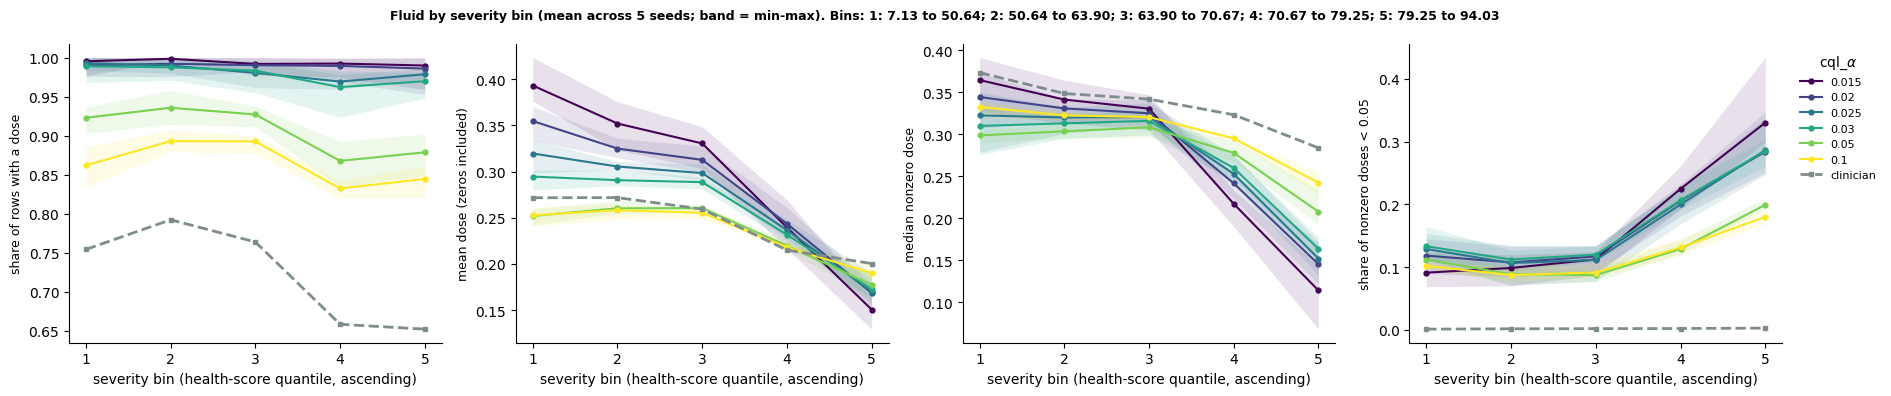

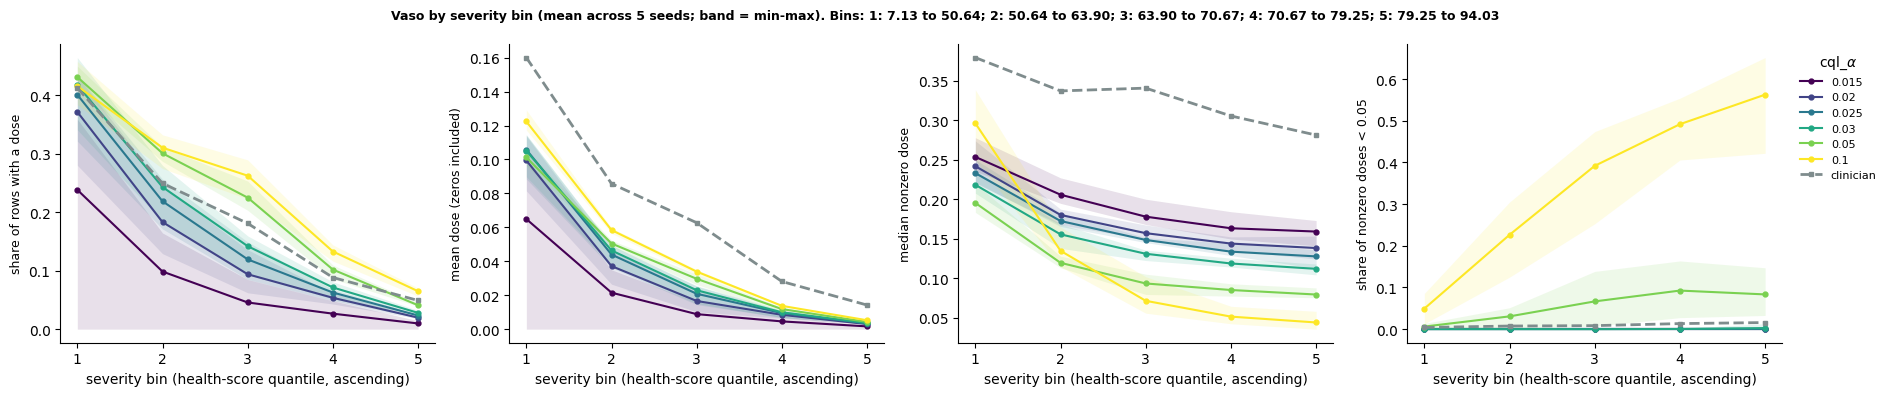

In [14]:
importlib.reload(dose_hist)

hs_val = dose_hist.collect_severity(cql_hs_models, store, split="val")

show = [0.015, 0.02, 0.025, 0.03, 0.05, 0.1]
sev = {}
for dim, name in [(0, "Fluid"), (1, "Vaso")]:
    sev[name] = dose_hist.dose_by_severity(actions_hs, clin_val, hs_val, dim, n_bins=5)
    df_s, clin_s, labels = sev[name]
    dose_hist.plot_dose_by_severity(df_s, clin_s, labels, name, show, save_path=None)

# Tables: clinician per bin, and seed-mean W1 / low share per alpha x bin for fluid
df_f, clin_f, labels = sev["Fluid"]
display(clin_f)
display(df_f[df_f.alpha.isin(show)].groupby(["alpha", "bin"])[["w1", "low_share", "fire_rate"]].mean().unstack("bin").round(3))

df_v, clin_v, labels = sev["Vaso"]
display(clin_v)
display(df_v[df_v.alpha.isin(show)].groupby(["alpha", "bin"])[["w1", "low_share", "fire_rate"]].mean().unstack("bin").round(3))

In [15]:
for name in ["Fluid", "Vaso"]:
    d = dm[name][dm[name].alpha.between(0.02, 0.04)]
    display(d.pivot(index="alpha", columns="seed", values="fire_rate").round(3))

seed,0,1,2,3,4
alpha,,,,,
0.0200,0.998,0.995,0.995,0.971,0.988
0.0210,0.998,0.982,0.987,0.987,0.980
0.0220,1.000,0.982,0.994,0.976,0.986
0.0240,0.988,0.987,0.986,0.988,0.981
0.0250,0.985,0.986,0.979,0.987,0.975
0.0260,0.985,0.984,0.981,0.988,0.980
0.0270,0.982,0.989,0.992,0.988,0.971
0.0280,0.982,0.980,0.986,0.986,0.964
0.0290,0.979,0.970,0.992,0.981,0.964


seed,0,1,2,3,4
alpha,,,,,
0.0200,0.159,0.140,0.107,0.178,0.139
0.0210,0.160,0.140,0.113,0.177,0.154
0.0220,0.165,0.151,0.116,0.182,0.155
0.0240,0.172,0.167,0.126,0.186,0.163
0.0250,0.174,0.166,0.130,0.185,0.171
0.0260,0.179,0.167,0.124,0.191,0.173
0.0270,0.182,0.175,0.123,0.191,0.180
0.0280,0.199,0.176,0.130,0.181,0.181
0.0290,0.191,0.177,0.140,0.186,0.186


In [16]:
import src.rl.alpha_candidate_table as cand
importlib.reload(cand)
gate = cand.degenerate_seed_gate(dm["Fluid"], dm["Vaso"])
limit = cand.max_eligible_alpha(df_hs)          # expect 0.07, the last alpha where every seed's own-critic advantage is positive
print("eligible up to:", limit, "| first clean alpha up to there:", cand.first_clean_alpha(gate, limit))

display(gate.loc[0.02:0.04])

cands = [0.015, 0.02, 0.025, 0.029, 0.03, 0.035, 0.05]
display(cand.candidate_table(df_hs, dm["Fluid"], dm["Vaso"], gate, cands).T)

eligible up to: 0.1 | first clean alpha up to there: 0.0325


,max_fluid_fire,fluid_degenerate_seeds,min_vaso_fire,vaso_degenerate_seeds,clean
alpha,,,,,
0.0200,0.998477,3,0.106870,0,False
0.0210,0.997868,1,0.112816,0,False
0.0220,0.999931,2,0.116361,0,False
0.0240,0.987837,0,0.125513,0,True
0.0250,0.986596,0,0.130184,0,True
0.0260,0.987711,0,0.124451,0,True
0.0270,0.991836,1,0.123244,0,False
0.0280,0.986292,0,0.129868,0,True
0.0290,0.991606,1,0.139693,0,False


alpha,0.015,0.020,0.025,0.029,0.030,0.035,0.050
sarsa_adv_mean,0.273,0.206,0.177,0.167,0.164,0.151,0.142
sarsa_adv_min,0.210,0.165,0.151,0.142,0.142,0.132,0.123
own_adv>0 (seeds),5.000,5.000,5.000,5.000,5.000,5.000,5.000
occupancy_mean,0.907,0.922,0.944,0.963,0.968,0.982,0.994
occupancy_min,0.876,0.907,0.936,0.955,0.960,0.975,0.993
fluid_fire_mean,0.994,0.990,0.982,0.977,0.978,0.943,0.906
fluid_fire_max,1.000,0.998,0.987,0.992,0.991,0.954,0.924
fluid_w1,0.106,0.090,0.080,0.077,0.078,0.071,0.078
fluid_low_share,0.171,0.166,0.166,0.169,0.171,0.140,0.122
vaso_fire_mean,0.084,0.144,0.165,0.176,0.180,0.196,0.220


In [17]:
import json, datetime
from src.rl.evaluate_cql_alpha_sweep import _models_by_alpha

final_alpha = 0.03
by_alpha = _models_by_alpha(cql_hs_models)
key = min(by_alpha, key=lambda a: abs(a - final_alpha))
assert abs(key - final_alpha) < 1e-12 and sorted(by_alpha[key]) == [0, 1, 2, 3, 4]

selection = {
    "reward": "health_score_change_only",
    "selected_on": "val",
    "alpha": final_alpha,
    "run_dirs": {int(s): str(m.record.run_dir) for s, m in sorted(by_alpha[key].items())},
    "criteria_in_order": [
        "own-critic advantage > 0 in every seed (pre-specified)",
        "no collapsed fluid/vaso gate in any seed, from the chosen alpha up to the eligible limit (added post hoc, after inspecting dose distributions)",
        "occupancy reasonable (>= 0.979 in every seed; not discriminating)",
        "highest SARSA advantage among the remaining, then judged on clinician-likeness of dose distributions (post hoc)",
    ],
    "eligible_limit_alpha": limit,
    "first_clean_alpha": cand.first_clean_alpha(gate, limit),
    "date": datetime.date.today().isoformat(),
}
print(json.dumps(selection, indent=2))
with open(sel_path := f"{cql_hs_dir}/final_alpha_selection.json", "w") as f:   # or wherever you keep analysis outputs
    json.dump(selection, f, indent=2)
print("saved to", sel_path)

{
  "reward": "health_score_change_only",
  "selected_on": "val",
  "alpha": 0.03,
  "run_dirs": {
    "0": "/home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/cql_with_logprobs/split_0/sepsis/combined_hourly_iv-vasoactive_inotropic_score/with_actions/health_score_change_only/alpha_sweep/mimic_iv_cql_with_logprobs_combined_hourly_iv-vasoactive_inotropic_score_single_hyperparameter_sweep_20261105_124309/unknown_cx3-20-2_20261106-025927_104ae1c3",
    "1": "/home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/cql_with_logprobs/split_0/sepsis/combined_hourly_iv-vasoactive_inotropic_score/with_actions/health_score_change_only/alpha_sweep/mimic_iv_cql_with_logprobs_combined_hourly_iv-vasoactive_inotropic_score_single_hyperparameter_sweep_20261105_124348/unknown_cx3-20-2_20261106-024949_fe089d26",
    "2": "/home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/cql_with_logprobs/split_0/sepsis/combined_hourly_iv-vasoactive_inotropic_score/with_actions/health_score_change

# standard deviation

{'floor': 0.1353352832366127, 'ceil': 2.718281828459045}


,n_mean,std_mean,std_p05,std_p95,frac_floor_worst,frac_ceil_worst,gate_sat_low_worst,gate_sat_high_worst
alpha,,,,,,,,
0.000,5599.0,0.747,0.259,0.924,0.078,0.000,0.0,0.987
0.015,19950.8,0.770,0.337,1.989,0.000,0.067,0.0,1.000
0.020,19935.0,0.786,0.346,2.368,0.000,0.085,0.0,1.000
0.025,19794.0,0.789,0.357,2.439,0.000,0.068,0.0,0.999
0.029,19847.2,0.811,0.348,2.645,0.000,0.087,0.0,0.999
0.030,19950.8,0.819,0.341,2.718,0.000,0.106,0.0,1.000
0.035,19996.2,0.840,0.312,2.718,0.000,0.135,0.0,1.000
0.050,19999.2,0.878,0.247,2.718,0.006,0.161,0.0,1.000
0.100,20000.0,0.942,0.184,2.718,0.034,0.197,0.0,1.000


,n_mean,std_mean,std_p05,std_p95,frac_floor_worst,frac_ceil_worst,gate_sat_low_worst,gate_sat_high_worst
alpha,,,,,,,,
0.000,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
0.015,1644.4,0.658,0.475,0.912,0.0,0.0,0.0,0.028
0.020,2811.0,0.652,0.482,0.877,0.0,0.0,0.0,0.030
0.025,3216.2,0.650,0.461,0.880,0.0,0.0,0.0,0.027
0.029,3423.8,0.659,0.450,0.901,0.0,0.0,0.0,0.016
0.030,3520.8,0.661,0.446,0.909,0.0,0.0,0.0,0.011
0.035,3826.4,0.670,0.427,0.936,0.0,0.0,0.0,0.005
0.050,4302.6,0.687,0.358,1.003,0.0,0.0,0.0,0.001
0.100,4631.8,0.727,0.287,1.321,0.0,0.0,0.0,0.060


,alpha,seed,dim,n,std_mean,frac_floor,frac_ceil


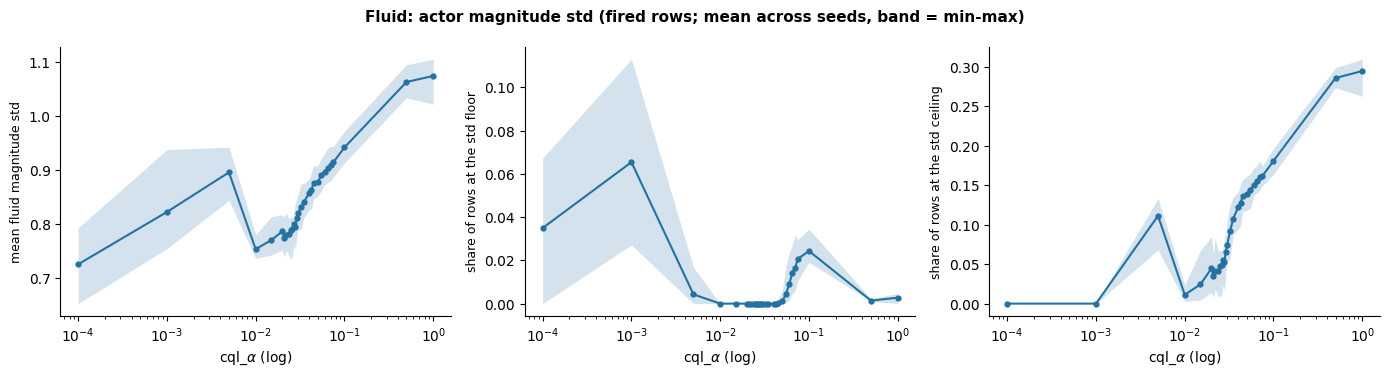

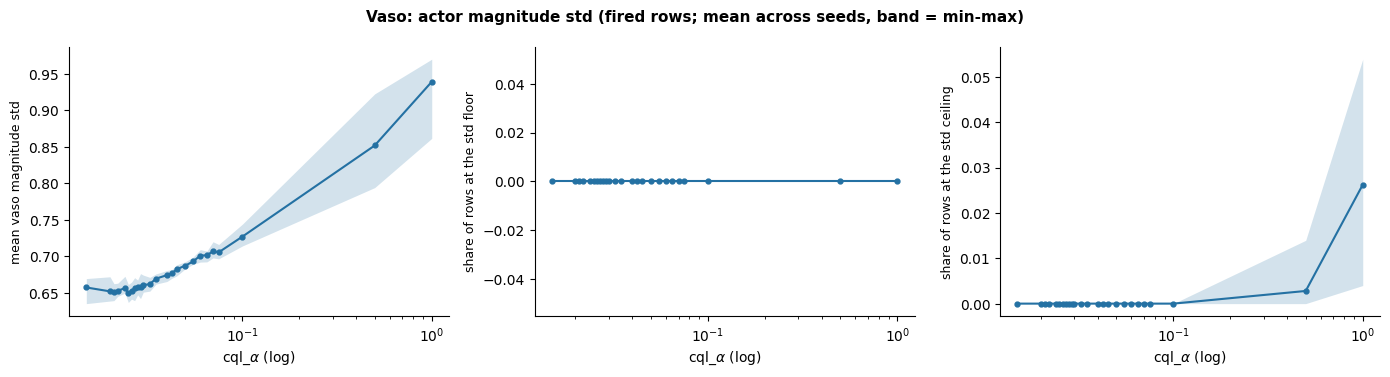

In [18]:
import src.rl.actor_std_check as stdchk
importlib.reload(stdchk)

import numpy as np
importlib.reload(stdchk)

std_hs = stdchk.actor_std_summary(cql_hs_models, store, split="val", bounds=(np.exp(-2), np.exp(1)))
print(std_hs[["floor", "ceil"]].iloc[0].to_dict())          # expect 0.135 and 2.718

for dim in ["Fluid", "Vaso"]:
    display(stdchk.summarize_std(std_hs, where="fired", dim=dim).loc[dim].loc[[0, 0.015, 0.02, 0.025, 0.029, 0.03, 0.035, 0.05, 0.1]].round(3))
    stdchk.plot_std_summary(std_hs, dim, where="fired", save_path=None)

display(stdchk.flag_stuck(std_hs, where="fired"))     # runs with >50% of fired rows at floor or ceiling

### Final-model selection: CQL α sweep (MIMIC-IV, health-score reward)

**What was compared.** 30 α values × 5 seeds, all on the **validation** split. The test split played no part in selection.

**The rule (frozen on CHOC, applied unchanged here).**
1. Eligible range: α below the first value at which any seed's own-critic advantage is ≤ 0. Here α ≤ 0.1; the first failure on the grid is α = 0.5 (mean −0.022, worst seed −0.031).
2. Acceptable: support ≥ 0.95 in every seed, and no degenerate seed (fluid fire rate < 0.99, vaso fire rate > 0.001). This must hold at that α and at every larger eligible α.
3. Choose the acceptable α with the highest mean SARSA advantage (normalised). Ties go to the lower α.

**Result: α = 0.0325** (`select_final_alpha_rule`). The five seeds at this α are the final models.

| | α = 0.0325 | Clinician |
|---|---|---|
| SARSA advantage, normalised: mean (SD across seeds) | 0.157 (0.015) | |
| Own-critic advantage > 0 | 5/5 seeds (min 0.0057) | |
| Support: mean (worst seed) | 0.974 (0.967) | |
| Fluid fire rate: mean (max) | 0.959 (0.982) | 0.724 |
| Vaso fire rate: mean (min) | 0.185 (0.162) | 0.196 |
| Fluid W1 to clinician (nonzero doses) | 0.072 | |
| Vaso W1 to clinician (nonzero doses) | 0.152 | |

**Why not a lower α.** SARSA advantage falls monotonically with α, so the rule picks the lowest acceptable α. Mean support reaches 0.95 at α = 0.027, but worst-seed support does not reach it until α = 0.029 (0.9496 at 0.028). At α = 0.027, 0.029 and 0.030 one seed (seed 2) gives fluid in ≥ 99% of states (99.18%, 99.16%, 99.07%). Because the checks must hold at every larger eligible α, the first acceptable value is 0.0325. The choice is insensitive to the support threshold for any value up to 0.967, because the degenerate-policy requirement binds first.

**Sensitivity.** Requiring the checks to hold at both adjacent swept α values (`neighbour_check=True`) moves the choice one grid step, to 0.035. Seed 2's fluid fire rate at 0.0325 is 0.982, within one percentage point of the 0.99 limit. It is 0.953 at 0.035.

**Descriptive caveats (not part of the rule).**
- The CQL policy gives fluid in 96% of states against 72% for clinicians. This is the opposite direction to CHOC.
- Low-dose share among fluid doses is 0.154 against 0.002 for clinicians.
- Median nonzero vaso dose is 0.164 against 0.345 for clinicians.
- As a sanity check, at α = 1.0 fire rates match the clinician's (fluid 0.725 vs 0.724; vaso 0.197 vs 0.196).

**What was and was not pre-specified.** The rule was developed on the CHOC sweep. Its degenerate-policy requirement was added after inspecting CHOC dose distributions, and the rule was then frozen. The MIMIC sweep was first run through an earlier cascade, which gave α = 0.0425, before the frozen rule was applied. The ratio-based stability gate in that cascade never triggered, since it measures the expected decline of advantage with α rather than instability.

In [19]:
final_alpha, rule_table = cand.select_final_alpha_rule(df_hs, dm["Fluid"], dm["Vaso"])
final_alpha_margin, rule_table_margin = cand.select_final_alpha_rule(df_hs, dm["Fluid"], dm["Vaso"], neighbour_check=True)

print(f"Final alpha (rule):                       {final_alpha}")
print(f"Final alpha (with neighbour_check=True):  {final_alpha_margin}")

Final alpha (rule):                       0.0325
Final alpha (with neighbour_check=True):  0.035


In [21]:
rule_table

,own_min,occ_min,sarsa_adv_mean,nondegenerate,occ_ok,ok_here,ok_from_here_up,neighbours_ok,acceptable
alpha,,,,,,,,,
0.0000,0.051895,0.654272,0.531798,False,False,False,False,False,False
0.0001,0.051991,0.660414,0.531505,False,False,False,False,False,False
0.0010,0.042449,0.670778,0.532279,False,False,False,False,False,False
0.0050,0.016983,0.808777,0.467734,False,False,False,False,False,False
0.0100,0.007556,0.865983,0.382928,False,False,False,False,False,False
0.0150,0.005953,0.875532,0.273447,False,False,False,False,False,False
0.0200,0.006021,0.906913,0.205969,False,False,False,False,False,False
0.0210,0.006083,0.912015,0.200137,False,False,False,False,False,False
0.0220,0.005936,0.915399,0.193770,False,False,False,False,False,False


# for paper:
Model selection. For each dataset and reward model we trained CQL policies over a grid of conservatism weights α (CHOC: 32 values; MIMIC-IV: 30 values), with five seeds each. All selection used the validation set only. For each policy we computed the advantage of the policy's action over the clinician's action under its own critic and under an independent SARSA critic, each normalised by the interquartile range of that critic's Q-values under clinician actions. We also computed state-action support, the fraction of validation states whose chosen (severity, fluid, vasopressor) bin occurred at least 10 times in training. The final α was the one with the highest mean SARSA advantage among values satisfying three requirements. First, own-critic advantage had to be positive in every seed; this defined the eligible range (CHOC α ≤ 0.07; MIMIC-IV α ≤ 0.1), above which the actor no longer improved on the clinician under its own training signal. Second, support had to be at least 0.95 in every seed. Third, no seed could have a degenerate policy (fluid given in at least 99% of states, or vasopressor in at most 0.1%). The second and third requirements had to hold at that α and at every larger eligible α. This selected α = 0.029 for CHOC and α = 0.0325 for MIMIC-IV. The five seeds at the selected α were used as the final models without retraining and were evaluated once on the held-out test set. The degenerate-policy requirement was added after inspecting CHOC validation dose distributions, and the rule was then frozen and applied unchanged to the MIMIC-IV and terminal-reward sweeps.


# test set evaluation

In [23]:
# 1) A store that also builds the test split; restrict the CQL models to the chosen alpha
store_test = D.DataStore(keep=("train", "val", "test"))
final_cql = {k: v for k, v in cql_hs_models.items()
             if any(abs(m.record.get("cql_alpha") - final_alpha) < 1e-12 for m in v.values())}
assert len(final_cql) == 1 and len(next(iter(final_cql.values()))) == 5

# 2) Seed pairing / row alignment on test
procs = store_test.processors(final_cql, split="test")
display(D.check_rows_aligned(next(iter(procs.values()))))

# 3) Advantages and occupancy on test (same function, split="test")
df_test = eval_cql.run_alpha_sweep_analysis(final_cql, sarsa_hs_models, store_test, split="test", n_severity_bins=200)
display(df_test.round(3))
display(eval_cql.summarize_by_alpha(df_test).T)

  building processors for state seed 0, shared reward [mimic_iv_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20261030_002923_675400_job4502770.pbs-7]  (splits: test, train, val)


using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
  building processors for state seed 1, shared reward [mimic_iv_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20261030_002923_675400_job4502770.pbs-7]  (splits: test, train, val)
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
  building processors for state seed 2, shared reward [mimic_iv_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20261030_002923_675400_job4502770.pbs-7]  (splits: test, train, val)
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_sc

,n_rows,same_index_ptr,same_actions,same_health_score,same_rewards,same_states
0,220015,True,True,True,True,True
1,220015,True,True,True,True,False
2,220015,True,True,True,True,False
3,220015,True,True,True,True,False
4,220015,True,True,True,True,False


alpha=0.0325     (deterministic, test, 5 seeds)  own_norm=+0.0071  sarsa_norm=+0.1553 [+0.1382, +0.1663]  occupancy=97.7%  (3.5s)


,alpha,seed,own_adv,own_adv_norm,sarsa_adv,sarsa_adv_norm,occupancy_frac,own_q_iqr,sarsa_q_iqr,n_rows
0,0.032,0,0.032,0.006,0.081,0.143,0.982,5.554,0.564,220015
1,0.032,1,0.034,0.008,0.118,0.163,0.973,4.144,0.724,220015
2,0.032,2,0.037,0.007,0.115,0.166,0.975,5.103,0.695,220015
3,0.032,3,0.036,0.008,0.098,0.138,0.981,4.711,0.707,220015
4,0.032,4,0.035,0.007,0.106,0.166,0.975,5.350,0.635,220015


alpha                  0.0325
own_adv        mean  0.034897
               min   0.032352
               max   0.037371
               std   0.001864
own_adv_norm   mean  0.007099
               min   0.005825
               max   0.008239
               std   0.000942
sarsa_adv      mean  0.103435
               min   0.080847
               max   0.118006
               std   0.014970
sarsa_adv_norm mean  0.155275
               min   0.138190
               max   0.166274
               std   0.013409
occupancy_frac mean  0.977129
               min   0.973034
               max   0.981947
               std   0.004008
n_seeds              5.000000

Saved to /home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/cql_with_logprobs/split_0/sepsis/combined_hourly_iv-vasoactive_inotropic_score/with_actions/health_score_change_only/alpha_sweep/dose_histogram_fluid_test.png


fire_rate                          w1                     low_share  \
            mean       min      max     mean       min       max      mean   
alpha                                                                        
0.0325  0.964253  0.931868  0.98541  0.07921  0.070027  0.088487  0.167775   

                        high_share           median_nz                      
            min     max       mean  min  max      mean       min       max  
alpha                                                                       
0.0325  0.16413  0.1706        0.0  0.0  0.0  0.271704  0.257376  0.290176

Saved to /home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/cql_with_logprobs/split_0/sepsis/combined_hourly_iv-vasoactive_inotropic_score/with_actions/health_score_change_only/alpha_sweep/dose_by_severity_fluid_test.png
Saved to /home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/cql_with_logprobs/split_0/sepsis/combined_hourly_iv-vasoactive_inotropic_score/with_actions/health_score_change_only/alpha_sweep/dose_histogram_vaso_test.png


fire_rate                           w1                     low_share  \
            mean      min       max      mean       min       max      mean   
alpha                                                                         
0.0325   0.18308  0.16957  0.201273  0.150764  0.141268  0.164191  0.000057   

                      high_share           median_nz                      
        min       max       mean  min  max      mean       min       max  
alpha                                                                     
0.0325  0.0  0.000181        0.0  0.0  0.0  0.179154  0.160933  0.188353

Saved to /home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/cql_with_logprobs/split_0/sepsis/combined_hourly_iv-vasoactive_inotropic_score/with_actions/health_score_change_only/alpha_sweep/dose_by_severity_vaso_test.png


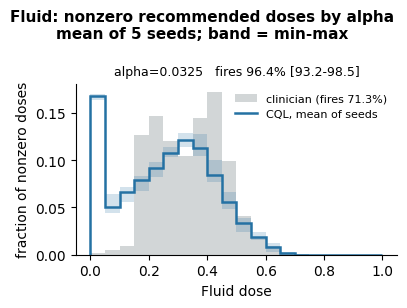

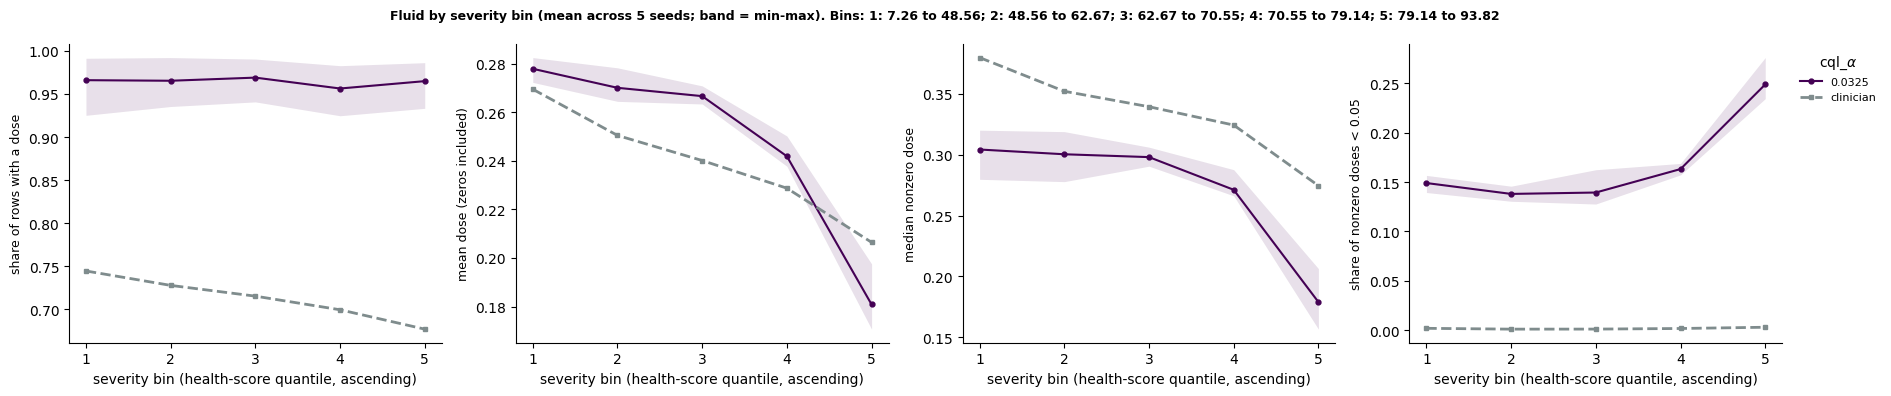

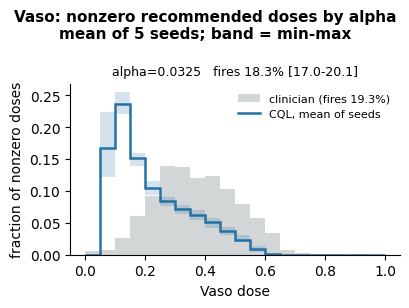

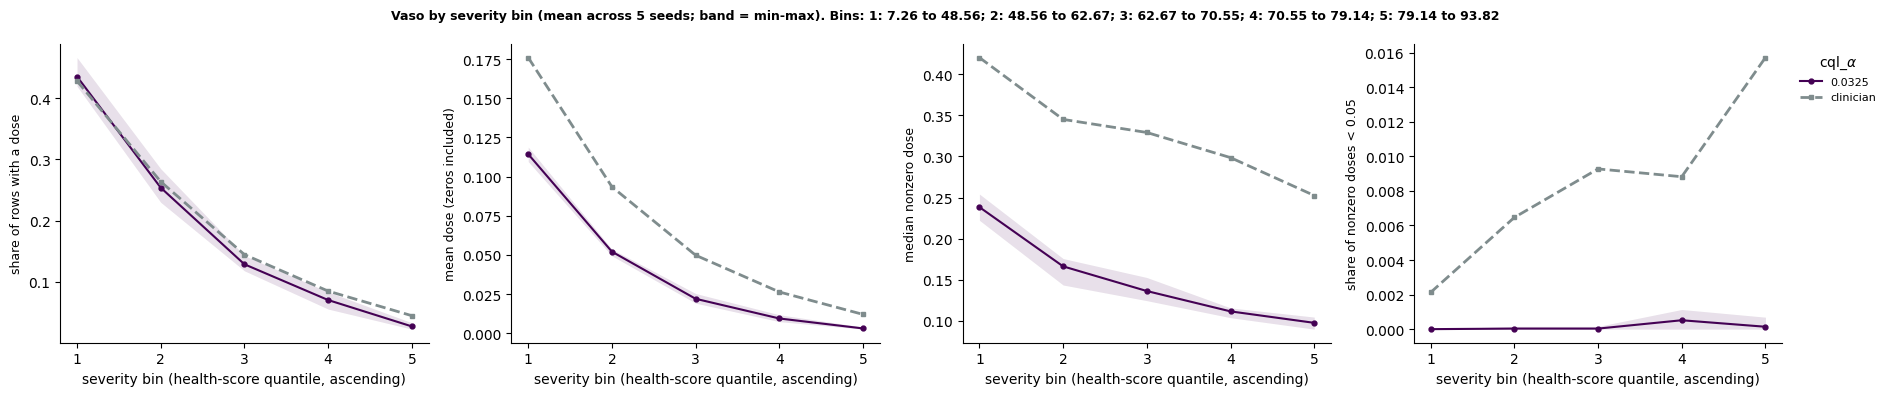

In [24]:
actions_t, clin_t = dose_hist.collect_actions(final_cql, store_test, split="test")
hs_t = dose_hist.collect_severity(final_cql, store_test, split="test")
for dim, name in [(0, "Fluid"), (1, "Vaso")]:
    dose_hist.plot_dose_histograms(actions_t, clin_t, dim=dim, dim_name=name, save_path=f"{cql_hs_dir}/dose_histogram_{name.lower()}_test.png")
    display(dose_hist.summarize_metrics(dose_hist.dose_distribution_metrics(actions_t, clin_t, dim)))
    df_s, clin_s, labels = dose_hist.dose_by_severity(actions_t, clin_t, hs_t, dim, n_bins=5)
    dose_hist.plot_dose_by_severity(df_s, clin_s, labels, name, [final_alpha], save_path=f"{cql_hs_dir}/dose_by_severity_{name.lower()}_test.png")

In [27]:
for dim, name in [(0, "Fluid"), (1, "Vaso")]:
    print(name, "val ", dose_hist.clinician_reference(clin_val, dim))
    print(name, "test", dose_hist.clinician_reference(clin_t, dim))

Fluid val  {'fire_rate': 0.7241472425065928, 'w1': 0.0, 'low_share': 0.0019438273563947954, 'high_share': 0.0, 'median_nz': 0.3404560089111328}
Fluid test {'fire_rate': 0.7129741154012227, 'w1': 0.0, 'low_share': 0.001740349982469002, 'high_share': 0.0, 'median_nz': 0.3428708612918854}
Vaso val  {'fire_rate': 0.1961988589682453, 'w1': 0.0, 'low_share': 0.007145157984128379, 'high_share': 2.928343436118188e-05, 'median_nz': 0.3447365462779999}
Vaso test {'fire_rate': 0.1932004636047542, 'w1': 0.0, 'low_share': 0.005599077798950761, 'high_share': 0.001082174700637542, 'median_nz': 0.3657756447792053}


Fluid val  {'fire_rate': 0.7241472425065928, 'w1': 0.0, 'low_share': 0.0019438273563947954, 'high_share': 0.0, 'median_nz': 0.3404560089111328}
Fluid test {'fire_rate': 0.7129741154012227, 'w1': 0.0, 'low_share': 0.001740349982469002, 'high_share': 0.0, 'median_nz': 0.3428708612918854}
Vaso val  {'fire_rate': 0.1961988589682453, 'w1': 0.0, 'low_share': 0.007145157984128379, 'high_share': 2.928343436118188e-05, 'median_nz': 0.3447365462779999}
Vaso test {'fire_rate': 0.1932004636047542, 'w1': 0.0, 'low_share': 0.005599077798950761, 'high_share': 0.001082174700637542, 'median_nz': 0.3657756447792053}

At the selected α = 0.0325, the five CQL policies retained positive advantage over clinician actions on the held-out test set under both their own critics and the independent SARSA critics (normalised SARSA advantage 0.155, SD 0.013; all seeds positive), with support of 0.977 (worst seed 0.973) and no degenerate seed. Validation and test values agreed to within the across-seed SD. The policies matched the clinician vasopressor rate closely (0.183 vs 0.193) but gave fluid substantially more often (0.964 vs 0.713), and with a larger share of very low doses and smaller median nonzero doses than clinicians (see Limitations).

In [28]:
adv_test = eval_cql.summarize_by_alpha(df_test).T

# Validation: same call, same settings, same models, so the two columns are like-for-like
df_val = eval_cql.run_alpha_sweep_analysis(final_cql, sarsa_hs_models, store_test, split="val", n_severity_bins=200)
adv_val = eval_cql.summarize_by_alpha(df_val).T
display(adv_val)  # should reproduce the validation sweep row for 0.0325

alpha=0.0325     (deterministic, val, 5 seeds)  own_norm=+0.0067  sarsa_norm=+0.1566 [+0.1387, +0.1751]  occupancy=97.4%  (3.0s)


alpha                  0.0325
own_adv        mean  0.034481
               min   0.032446
               max   0.035593
               std   0.001271
own_adv_norm   mean  0.006736
               min   0.005653
               max   0.007886
               std   0.000883
sarsa_adv      mean  0.098180
               min   0.073944
               max   0.115343
               std   0.016266
sarsa_adv_norm mean  0.156638
               min   0.138703
               max   0.175113
               std   0.015087
occupancy_frac mean  0.974388
               min   0.967246
               max   0.979897
               std   0.005384
n_seeds              5.000000

In [29]:
actions_test, clin_test = dose_hist.collect_actions(final_cql, store_test, split="test")

dm_test = {name: dose_hist.dose_distribution_metrics(actions_test, clin_test, dim)
           for dim, name in [(0, "Fluid"), (1, "Vaso")]}

In [30]:
df_final = cand.final_model_table(
    0.0325,
    splits={"Validation": (adv_val, dm), "Test": (adv_test, dm_test)},
    clin={s: {n: dose_hist.clinician_reference(c, d) for d, n in [(0, "Fluid"), (1, "Vaso")]}
          for s, c in [("Validation", clin_val), ("Test", clin_test)]},
    summarize_metrics=dose_hist.summarize_metrics,
)
display(df_final)

,Validation,Test,Clinician (val / test)
"SARSA advantage, normalised: mean (SD)",0.157 (0.015),0.155 (0.013),
"Own-critic advantage, normalised: mean (min)",0.0067 (0.0057),0.0071 (0.0058),
Support: mean (worst seed),0.974 (0.967),0.977 (0.973),
Fluid fire rate: mean (range),0.959 (0.933-0.982),0.964 (0.932-0.985),0.724 / 0.713
Vaso fire rate: mean (range),0.185 (0.162-0.204),0.183 (0.170-0.201),0.196 / 0.193
Fluid W1 to clinician,0.072,0.079,
Vaso W1 to clinician,0.152,0.151,
Fluid low-dose share,0.1537,0.1678,0.0019 / 0.0017
Vaso low-dose share,0.0000,0.0001,0.0071 / 0.0056
Fluid median nonzero dose,0.283,0.272,0.340 / 0.343


# test set evaluation on model with actions omitted from states and rewards

In [50]:
cql_hs_na_dir = os.path.join(cql_model_dir, "without_actions", "health_score_change_only", "alpha_sweep")
sarsa_hs_na_dir = os.path.join(basic_q_dir, "without_actions", "health_score_change_only", "five_seeds")

print(f"Using cql_hs_na_dir: {cql_hs_na_dir}")
print(f"Using sarsa_hs_na_dir: {sarsa_hs_na_dir}")

Using cql_hs_na_dir: /home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/cql_with_logprobs/split_0/sepsis/combined_hourly_iv-vasoactive_inotropic_score/without_actions/health_score_change_only/alpha_sweep
Using sarsa_hs_na_dir: /home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/basic_q/split_0/sepsis/combined_hourly_iv-vasoactive_inotropic_score/without_actions/health_score_change_only/five_seeds


In [51]:
hs_na_study = R.make_study(cql_hs_na_dir, group_by=("cql_alpha",), name="CQL alpha sweep (health score)")
hs_na_study = hs_na_study.complete(seeds=range(5))     # drops any alpha missing a seed, and prints which
_ = hs_na_study.check(ignore=R.DEFAULT_IGNORE_KEYS | {"ratio_of_fluid_to_vaso"})
sarsa_hs_na_study = R.make_study(sarsa_hs_na_dir, name="SARSA (health score)")
_ = sarsa_hs_na_study.check(ignore=R.DEFAULT_IGNORE_KEYS | {"ratio_of_fluid_to_vaso"})

cql_hs_na_models = M.load_study_models(hs_na_study)
sarsa_hs_na_models = M.load_study_models(sarsa_hs_na_study)

Study 'CQL alpha sweep (health score)': kept 1 of 1 group(s) with seeds [0, 1, 2, 3, 4]
Study 'CQL alpha sweep (health score)': 1 group(s), 5 run(s), seeds [0, 1, 2, 3, 4]
  OK
  overrides applied under /home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/basic_q/split_0/sepsis/combined_hourly_iv-vasoactive_inotropic_score/without_actions/health_score_change_only/five_seeds:
    vaso_reward_coefficient: saved=0.1 -> used=0.0  [rule vaso_reward_gate: add_reward_to_vaso_dosing is False]  seeds=[0, 1, 2, 3, 4]
Study 'SARSA (health score)': 1 group(s), 5 run(s), seeds [0, 1, 2, 3, 4]
  OK
  loaded LoadedModel(CQL alpha sweep (health score) cql_alpha=0.0325 seed 0: actor, critic)
  loaded LoadedModel(CQL alpha sweep (health score) cql_alpha=0.0325 seed 1: actor, critic)
  loaded LoadedModel(CQL alpha sweep (health score) cql_alpha=0.0325 seed 2: actor, critic)
  loaded LoadedModel(CQL alpha sweep (health score) cql_alpha=0.0325 seed 3: actor, critic)
  loaded LoadedModel(CQL alpha sw

In [ ]:
ids = hs_na_study.data_identities().values()
assert len(hs_na_study.data_identities()) == 5
assert all("without_actions" in v.state_source for v in ids), "CQL runs aren't on the no-actions states"
assert {v.short() for v in sarsa_hs_na_study.data_identities().values()} <= {v.short() for v in ids}, \
    "SARSA judges don't share the CQL state embeddings"

In [56]:
# 1) A store that also builds the test split; restrict the CQL models to the chosen alpha
final_alpha = 0.0325
store_test_na = D.DataStore(keep=("train", "val", "test"))
final_cql_na = {k: v for k, v in cql_hs_na_models.items()
                if any(abs(m.record.get("cql_alpha") - final_alpha) < 1e-12 for m in v.values())}
assert len(final_cql_na) == 1 and len(next(iter(final_cql_na.values()))) == 5

# 2) Seed pairing / row alignment on test
procs_na = store_test_na.processors(final_cql_na, split="test")
display(D.check_rows_aligned(next(iter(procs_na.values()))))

# 3) Advantages and occupancy on test (same function, split="test")
df_test_na = eval_cql.run_alpha_sweep_analysis(final_cql_na, sarsa_hs_na_models, store_test_na, split="test", n_severity_bins=200)
display(df_test_na.round(3))
display(eval_cql.summarize_by_alpha(df_test_na).T)

  building processors for state seed 0, shared reward [mimic_iv_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20261030_201643_142620_job4506330.pbs-7]  (splits: test, train, val)
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
  building processors for state seed 1, shared reward [mimic_iv_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20261030_201643_142620_job4506330.pbs-7]  (splits: test, train, val)
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
  building processors for state seed 2, shared reward [mimic_iv_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20261030_201643_142620_job4506330.pbs-7]  (splits: test

,n_rows,same_index_ptr,same_actions,same_health_score,same_rewards,same_states
0,220015,True,True,True,True,True
1,220015,True,True,True,True,False
2,220015,True,True,True,True,False
3,220015,True,True,True,True,False
4,220015,True,True,True,True,False


alpha=0.0325     (deterministic, test, 5 seeds)  own_norm=+0.0386  sarsa_norm=+0.1569 [+0.1108, +0.1925]  occupancy=79.1%  (3.7s)


,alpha,seed,own_adv,own_adv_norm,sarsa_adv,sarsa_adv_norm,occupancy_frac,own_q_iqr,sarsa_q_iqr,n_rows
0,0.032,0,0.043,0.036,0.109,0.193,0.780,1.194,0.568,220015
1,0.032,1,0.041,0.041,0.108,0.173,0.771,1.010,0.627,220015
2,0.032,2,0.045,0.038,0.121,0.181,0.791,1.200,0.670,220015
3,0.032,3,0.044,0.039,0.107,0.111,0.759,1.125,0.964,220015
4,0.032,4,0.043,0.039,0.094,0.127,0.852,1.091,0.737,220015


alpha                  0.0325
own_adv        mean  0.043279
               min   0.041421
               max   0.045477
               std   0.001535
own_adv_norm   mean  0.038597
               min   0.035857
               max   0.041019
               std   0.001897
sarsa_adv      mean  0.107910
               min   0.093802
               max   0.121034
               std   0.009681
sarsa_adv_norm mean  0.156867
               min   0.110805
               max   0.192547
               std   0.035730
occupancy_frac mean  0.790653
               min   0.758857
               max   0.852137
               std   0.036341
n_seeds              5.000000

Saved to /home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/cql_with_logprobs/split_0/sepsis/combined_hourly_iv-vasoactive_inotropic_score/without_actions/health_score_change_only/alpha_sweep/dose_histogram_fluid_test.png


fire_rate                            w1                     low_share  \
            mean       min       max      mean       min       max      mean   
alpha                                                                          
0.0325  0.596292  0.486194  0.717951  0.282204  0.160149  0.360304  0.003409   

                      high_share                     median_nz            \
        min       max       mean       min       max      mean       min   
alpha                                                                      
0.0325  0.0  0.017045   0.153724  0.046999  0.235239  0.578909  0.472943   

                  
             max  
alpha             
0.0325  0.653511

Saved to /home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/cql_with_logprobs/split_0/sepsis/combined_hourly_iv-vasoactive_inotropic_score/without_actions/health_score_change_only/alpha_sweep/dose_by_severity_fluid_test.png
Saved to /home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/cql_with_logprobs/split_0/sepsis/combined_hourly_iv-vasoactive_inotropic_score/without_actions/health_score_change_only/alpha_sweep/dose_histogram_vaso_test.png


fire_rate             w1         low_share         high_share          \
            mean  min  max mean min max      mean min max       mean min max   
alpha                                                                          
0.0325       0.0  0.0  0.0  NaN NaN NaN       NaN NaN NaN        NaN NaN NaN   

       median_nz          
            mean min max  
alpha                     
0.0325       NaN NaN NaN

Saved to /home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/cql_with_logprobs/split_0/sepsis/combined_hourly_iv-vasoactive_inotropic_score/without_actions/health_score_change_only/alpha_sweep/dose_by_severity_vaso_test.png


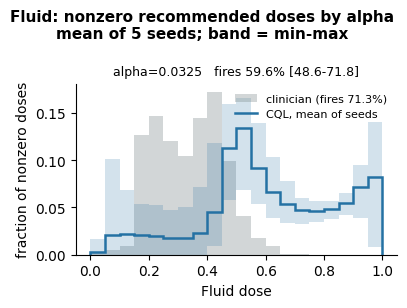

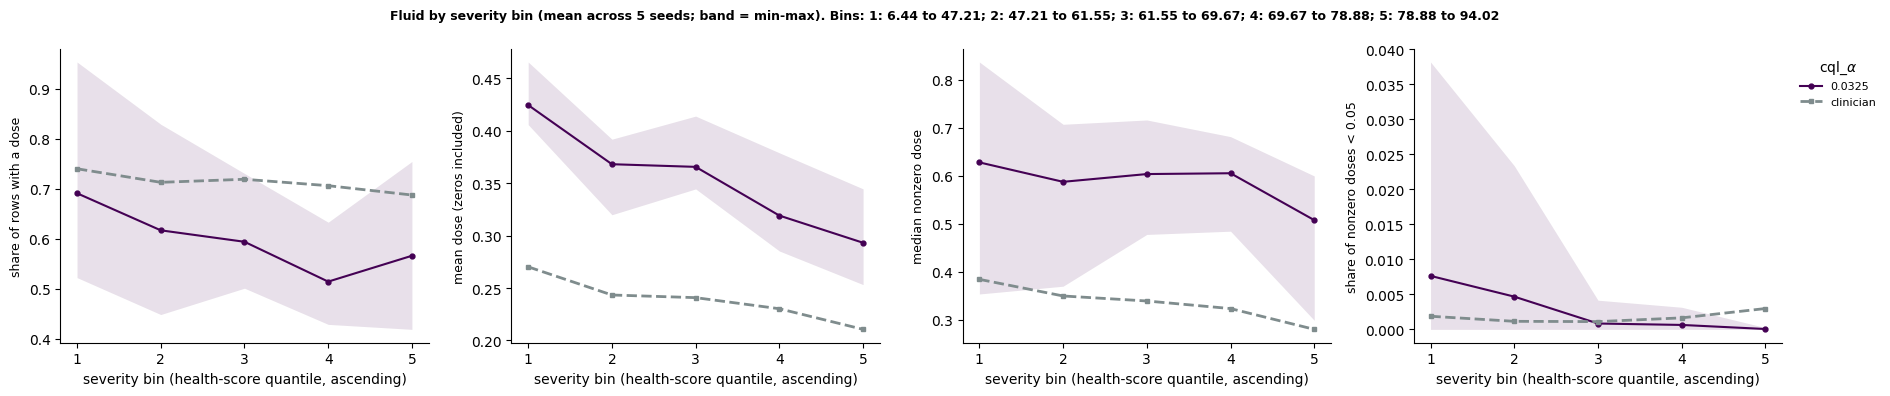

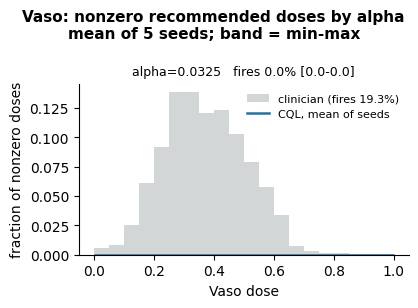

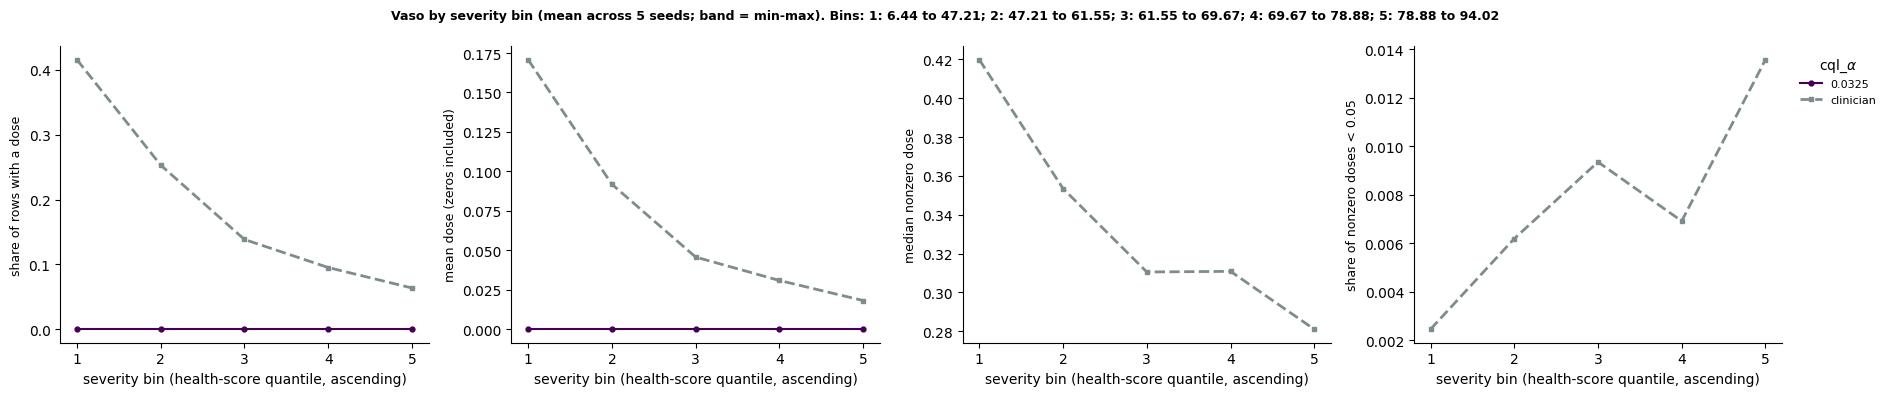

In [57]:
actions_t_na, clin_t_na = dose_hist.collect_actions(final_cql_na, store_test_na, split="test")
hs_t_na = dose_hist.collect_severity(final_cql_na, store_test_na, split="test")
for dim, name in [(0, "Fluid"), (1, "Vaso")]:
    dose_hist.plot_dose_histograms(actions_t_na, clin_t_na, dim=dim, dim_name=name, save_path=f"{cql_hs_na_dir}/dose_histogram_{name.lower()}_test.png")
    display(dose_hist.summarize_metrics(dose_hist.dose_distribution_metrics(actions_t_na, clin_t_na, dim)))
    df_s_na, clin_s_na, labels_na = dose_hist.dose_by_severity(actions_t_na, clin_t_na, hs_t_na, dim, n_bins=5)
    dose_hist.plot_dose_by_severity(df_s_na, clin_s_na, labels_na, name, [final_alpha], save_path=f"{cql_hs_na_dir}/dose_by_severity_{name.lower()}_test.png")

# load terminal models

# Terminal-reward CQL alpha sweep: summary

## Setup
- CQL alpha sweep with a Monte Carlo terminal reward on MIMIC-IV sepsis data (split 0), evaluated on the **val** split only.
- 32 alpha values from 0 to 1, 5 seeds each (160 runs).
- Each CQL seed is judged by the SARSA terminal critic of the same seed.
- Same DeepHit states and reward sources as the health-score sweep; the only reward-related difference is `reward_type`.
- Checks passed: study consistency (`check()`), judge pairing (seed and state embedding), and reward signature (`terminal` for both CQL and SARSA).
- Advantages are normalised by the IQR of Q under clinician actions.

## Results
- **SARSA advantage (independent critic)**
  - Highest at alpha 0-0.001 (about 0.058), where occupancy is near zero.
  - Falls to 0.016 at alpha 0.005 as occupancy reaches 70%.
  - All 5 seeds positive for alpha 0.015-0.027 (0.0045 to 0.0021), with occupancy 87-91%.
  - Seeds start to disagree around alpha 0.03; the mean crosses zero near 0.055.
  - Alpha 0.5 and 1: all 5 seeds negative (-0.0043, -0.0050).
- **Own-critic advantage**
  - Minimum of 0.0085 near alpha 0.015, then rises to 0.023 at alpha 1.
  - The rise is in the raw advantage (0.044 to 0.114), not a normalisation artefact.
  - Self-assessed optimism: it diverges from the SARSA advantage at high alpha.
- **Occupancy support**
  - Peaks at about 91% near alpha 0.02, dips to about 84% at alpha 0.06-0.1, and rises to 94% at alpha 1.

## Stability gate
- `sarsa_stability` gives an onset of alpha = 0.0001. This is an artefact of the window-ratio rule: it reads the real early drop in the mean SARSA advantage (alpha 0.001 to 0.005) as instability and then flags every alpha at or above the onset.
- `select_final_alpha` would therefore return alpha = 0 (0% occupancy). The gate is not informative for this sweep.

## Conclusion
- The learned policies are degenerate: fluid is bimodal at its minimum and maximum, and vaso is close to zero everywhere.
- Even the best-supported alpha has a SARSA advantage of only about 0.005 of the Q IQR.
- CQL with Monte Carlo terminal rewards did not produce usable policies; no alpha should be selected from this sweep.

## Caveats
- Bracketed ranges in the sweep log are min-max across 5 seeds, not confidence intervals.
- The explanation for the degenerate policies (CQL penalty swamping a sparse reward, or critics that barely depend on the action) is a hypothesis and has not been tested.

## Next
- Analyse the terminal SARSA critics: action sensitivity, calibration against realised outcomes, and Bellman fit.
- Compare with the health-score SARSA critics.

In [32]:
term_study = R.make_study(cql_term_dir, group_by=("cql_alpha",), name="CQL alpha sweep (health score)")
_ = term_study.check(ignore=R.DEFAULT_IGNORE_KEYS | {"ratio_of_fluid_to_vaso"})

import pandas as pd
have = pd.crosstab([k[0] for k, s, r in term_study.items()], [s for k, s, r in term_study.items()])
have[(have != 1).any(axis=1)]

Study 'CQL alpha sweep (health score)': 32 group(s), 160 run(s), seeds [0, 1, 2, 3, 4]
  between groups:
      cql_alpha                                {'cql_alpha=0.0': 0.0, 'cql_alpha=0.0001': 0.0001, 'cql_alpha=0.001': 0.001, 'cql_alpha=0.005': 0.005, 'cql_alpha=0.01': 0.01, 'cql_alpha=0.015': 0.015, 'cql_alpha=0.02': 0.02, 'cql_alpha=0.021': 0.021, 'cql_alpha=0.022': 0.022, 'cql_alpha=0.023': 0.023, 'cql_alpha=0.024': 0.024, 'cql_alpha=0.025': 0.025, 'cql_alpha=0.026': 0.026, 'cql_alpha=0.027': 0.027, 'cql_alpha=0.028': 0.028, 'cql_alpha=0.029': 0.029, 'cql_alpha=0.03': 0.03, 'cql_alpha=0.0325': 0.0325, 'cql_alpha=0.035': 0.035, 'cql_alpha=0.0375': 0.0375, 'cql_alpha=0.04': 0.04, 'cql_alpha=0.0425': 0.0425, 'cql_alpha=0.045': 0.045, 'cql_alpha=0.05': 0.05, 'cql_alpha=0.055': 0.055, 'cql_alpha=0.06': 0.06, 'cql_alpha=0.065': 0.065, 'cql_alpha=0.07': 0.07, 'cql_alpha=0.075': 0.075, 'cql_alpha=0.1': 0.1, 'cql_alpha=0.5': 0.5, 'cql_alpha=1.0': 1.0}
  OK


col_0,0,1,2,3,4
row_0,,,,,


In [37]:
term_study = R.make_study(cql_term_dir, group_by=("cql_alpha",), name="CQL alpha sweep (health score)")
term_study = term_study.complete(seeds=range(5))     # drops any alpha missing a seed, and prints which
_ = term_study.check(ignore=R.DEFAULT_IGNORE_KEYS | {"ratio_of_fluid_to_vaso"})
sarsa_term_study = R.make_study(sarsa_term_dir, name="SARSA (health score)")
_ = sarsa_term_study.check(ignore=R.DEFAULT_IGNORE_KEYS | {"ratio_of_fluid_to_vaso"})

cql_term_models = M.load_study_models(term_study)
sarsa_term_models = M.load_study_models(sarsa_term_study)

Study 'CQL alpha sweep (health score)': kept 32 of 32 group(s) with seeds [0, 1, 2, 3, 4]
Study 'CQL alpha sweep (health score)': 32 group(s), 160 run(s), seeds [0, 1, 2, 3, 4]
  between groups:
      cql_alpha                                {'cql_alpha=0.0': 0.0, 'cql_alpha=0.0001': 0.0001, 'cql_alpha=0.001': 0.001, 'cql_alpha=0.005': 0.005, 'cql_alpha=0.01': 0.01, 'cql_alpha=0.015': 0.015, 'cql_alpha=0.02': 0.02, 'cql_alpha=0.021': 0.021, 'cql_alpha=0.022': 0.022, 'cql_alpha=0.023': 0.023, 'cql_alpha=0.024': 0.024, 'cql_alpha=0.025': 0.025, 'cql_alpha=0.026': 0.026, 'cql_alpha=0.027': 0.027, 'cql_alpha=0.028': 0.028, 'cql_alpha=0.029': 0.029, 'cql_alpha=0.03': 0.03, 'cql_alpha=0.0325': 0.0325, 'cql_alpha=0.035': 0.035, 'cql_alpha=0.0375': 0.0375, 'cql_alpha=0.04': 0.04, 'cql_alpha=0.0425': 0.0425, 'cql_alpha=0.045': 0.045, 'cql_alpha=0.05': 0.05, 'cql_alpha=0.055': 0.055, 'cql_alpha=0.06': 0.06, 'cql_alpha=0.065': 0.065, 'cql_alpha=0.07': 0.07, 'cql_alpha=0.075': 0.075, 'cql_alpha=0.

## load data

In [39]:
print(len(term_study.data_identities()), "CQL identities (expect 5);",
      {v.short() for v in sarsa_term_study.data_identities().values()} <=
      {v.short() for v in term_study.data_identities().values()}, "(SARSA shares them)")

store = D.DataStore(keep=("train", "val"))
paired = store.pair({k: v for k, v in cql_term_models.items() if k == (0.03,)}, split="val")
display(D.check_rows_aligned({s: p for s, (m, p) in paired[(0.03,)].items()}))

5 CQL identities (expect 5); True (SARSA shares them)
  building processors for state seed 0, shared reward [mimic_iv_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20261030_002923_675400_job4502770.pbs-7]  (splits: train, val)
using shifted actions for RL dataset
Using terminal reward type
using shifted actions for RL dataset
Using terminal reward type
using shifted actions for RL dataset
Using terminal reward type
  building processors for state seed 1, shared reward [mimic_iv_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20261030_002923_675400_job4502770.pbs-7]  (splits: train, val)
using shifted actions for RL dataset
Using terminal reward type
using shifted actions for RL dataset
Using terminal reward type
using shifted actions for RL dataset
Using terminal reward type
  building processors for state seed 2, shared reward [mimic_iv_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20261030_002923_675400_job4502770.pbs

,n_rows,same_index_ptr,same_actions,same_health_score,same_rewards,same_states
0,174053,True,True,True,True,True
1,174053,True,True,True,True,False
2,174053,True,True,True,True,False
3,174053,True,True,True,True,False
4,174053,True,True,True,True,False


# run sweep

In [40]:
df_term = eval_cql.run_alpha_sweep_analysis(cql_term_models, sarsa_term_models, store, n_severity_bins=200)
display(eval_cql.summarize_by_alpha(df_term))

alpha=0          (deterministic, val, 5 seeds)  own_norm=+0.1068  sarsa_norm=+0.0577 [+0.0270, +0.0746]  occupancy=0.0%  (3.0s)
alpha=0.0001     (deterministic, val, 5 seeds)  own_norm=+0.1021  sarsa_norm=+0.0577 [+0.0270, +0.0746]  occupancy=0.0%  (1.9s)
alpha=0.001      (deterministic, val, 5 seeds)  own_norm=+0.0642  sarsa_norm=+0.0587 [+0.0303, +0.0769]  occupancy=4.9%  (2.0s)
alpha=0.005      (deterministic, val, 5 seeds)  own_norm=+0.0139  sarsa_norm=+0.0163 [+0.0090, +0.0230]  occupancy=70.4%  (2.0s)
alpha=0.01       (deterministic, val, 5 seeds)  own_norm=+0.0086  sarsa_norm=+0.0067 [-0.0014, +0.0094]  occupancy=85.1%  (1.9s)
alpha=0.015      (deterministic, val, 5 seeds)  own_norm=+0.0085  sarsa_norm=+0.0045 [+0.0024, +0.0086]  occupancy=90.6%  (1.9s)
alpha=0.02       (deterministic, val, 5 seeds)  own_norm=+0.0092  sarsa_norm=+0.0040 [+0.0014, +0.0074]  occupancy=90.9%  (1.9s)
alpha=0.021      (deterministic, val, 5 seeds)  own_norm=+0.0094  sarsa_norm=+0.0033 [+0.0011, +0.00

own_adv                               own_adv_norm            \
            mean       min       max       std         mean       min   
alpha                                                                   
0.0000  0.548436  0.484488  0.605238  0.044963     0.106819  0.094150   
0.0001  0.524122  0.461829  0.580491  0.044750     0.102085  0.089759   
0.0010  0.329220  0.286838  0.382198  0.037995     0.064190  0.055765   
0.0050  0.070784  0.050012  0.100021  0.018689     0.013886  0.009368   
0.0100  0.044130  0.030132  0.054690  0.010081     0.008632  0.005989   
0.0150  0.043546  0.035172  0.052474  0.006543     0.008517  0.007004   
0.0200  0.047080  0.040040  0.063100  0.009154     0.009216  0.007525   
0.0210  0.047841  0.040719  0.063787  0.009126     0.009367  0.007657   
0.0220  0.049994  0.041980  0.064658  0.009469     0.009788  0.007897   
0.0230  0.048795  0.042427  0.064843  0.009119     0.009554  0.007977   
0.0240  0.050788  0.042983  0.065021  0.009281     0.009946  0.008087   
0.0250  0.051726  0.044095  0.065803  0.009240     0.010130  0.008296   
0.0260  0.052294  0.044785  0.065826  0.008869     0.010245  0.008430   
0.0270  0.054793  0.047862  0.065612  0.007341     0.010723  0.009565   
0.0280  0.055343  0.048264  0.065911  0.007168     0.010834  0.009650   
0.0290  0.055895  0.049212  0.065830  0.006781     0.010945  0.009839   
0.0300  0.056669  0.050229  0.065845  0.006471     0.011100  0.010043   
0.0325  0.058574  0.052543  0.067369  0.006210     0.011476  0.010545   
0.0350  0.060342  0.054101  0.068922  0.006199     0.011828  0.010928   
0.0375  0.062077  0.055591  0.070431  0.006296     0.012169  0.011229   
0.0400  0.063816  0.057006  0.072423  0.006264     0.012514  0.011539   
0.0425  0.065406  0.058372  0.073914  0.006245     0.012831  0.011821   
0.0450  0.066653  0.059654  0.074695  0.005977     0.013077  0.012085   
0.0500  0.069232  0.062279  0.076452  0.005601     0.013586  0.012624   
0.0550  0.072284  0.065019  0.079532  0.005600     0.014189  0.013186   
0.0600  0.074845  0.067913  0.082155  0.005436     0.014697  0.013775   
0.0650  0.077365  0.070486  0.084575  0.005305     0.015202  0.014293   
0.0700  0.079767  0.073013  0.086792  0.005153     0.015684  0.014810   
0.0750  0.081793  0.075210  0.088685  0.004977     0.016094  0.015251   
0.1000  0.090027  0.083440  0.096369  0.004679     0.017731  0.016874   
0.5000  0.113744  0.109264  0.117641  0.002998     0.023044  0.022726   
1.0000  0.114104  0.109159  0.116517  0.002983     0.023440  0.023140   

                           sarsa_adv            ...           sarsa_adv_norm  \
             max       std      mean       min  ...       std           mean   
alpha                                           ...                            
0.0000  0.119637  0.009540  0.285750  0.130131  ...  0.092771       0.057680   
0.0001  0.114727  0.009448  0.285996  0.130100  ...  0.092789       0.057727   
0.0010  0.075640  0.008017  0.290461  0.145673  ...  0.091255       0.058659   
0.0050  0.020149  0.004018  0.080838  0.043444  ...  0.028358       0.016330   
0.0100  0.010709  0.002040  0.033169 -0.006792  ...  0.022652       0.006692   
0.0150  0.010214  0.001315  0.022235  0.011687  ...  0.011985       0.004538   
0.0200  0.012302  0.001805  0.019703  0.006634  ...  0.011061       0.004016   
0.0210  0.012433  0.001800  0.016242  0.005257  ...  0.011387       0.003303   
0.0220  0.012603  0.001854  0.015614  0.008466  ...  0.010209       0.003183   
0.0230  0.012646  0.001796  0.015225  0.007160  ...  0.010305       0.003105   
0.0240  0.012681  0.001812  0.013212  0.006810  ...  0.010084       0.002696   
0.0250  0.012836  0.001802  0.012175  0.005198  ...  0.010105       0.002487   
0.0260  0.012840  0.001731  0.011632  0.004605  ...  0.010196       0.002380   
0.0270  0.012800  0.001334  0.010068  0.001664  ...  0.010037       0.002066   
0.0280  0.012867  0.001285  0.008620 -0.001634  ...  0.011272       0.001780   
0.0290  0.012

Note: alpha=0 excluded from plot (log scale can't show it).
Saved to /home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/cql_with_logprobs/split_0/sepsis/combined_hourly_iv-vasoactive_inotropic_score/cql_alpha_sweep_terminal.png
Note: alpha=0 excluded from plot (log scale can't show it).
Saved to /home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/cql_with_logprobs/split_0/sepsis/combined_hourly_iv-vasoactive_inotropic_score/cql_alpha_sweep_combined_terminal.png


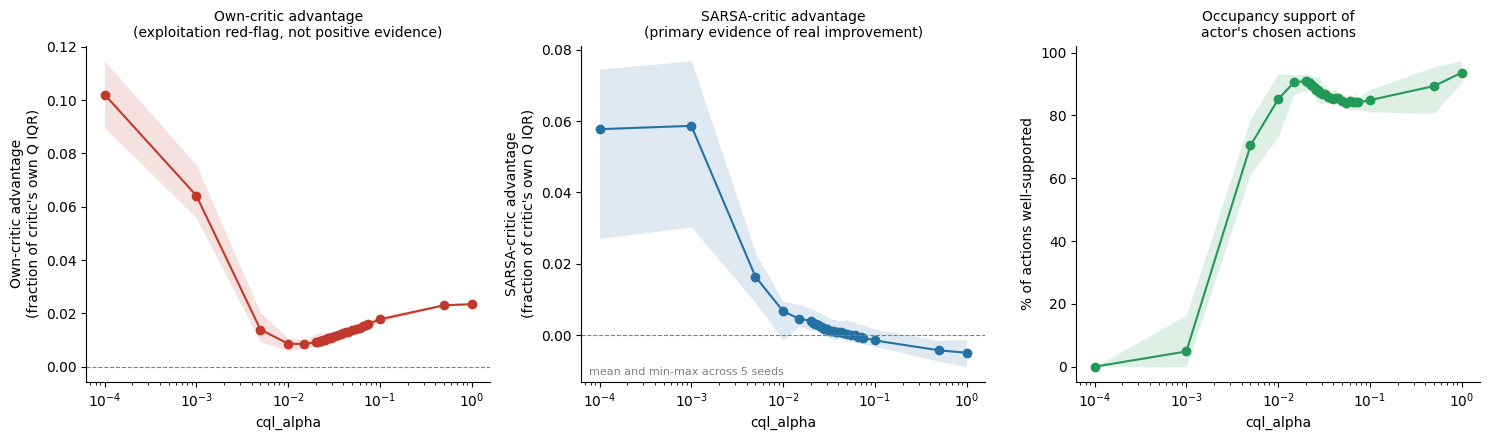

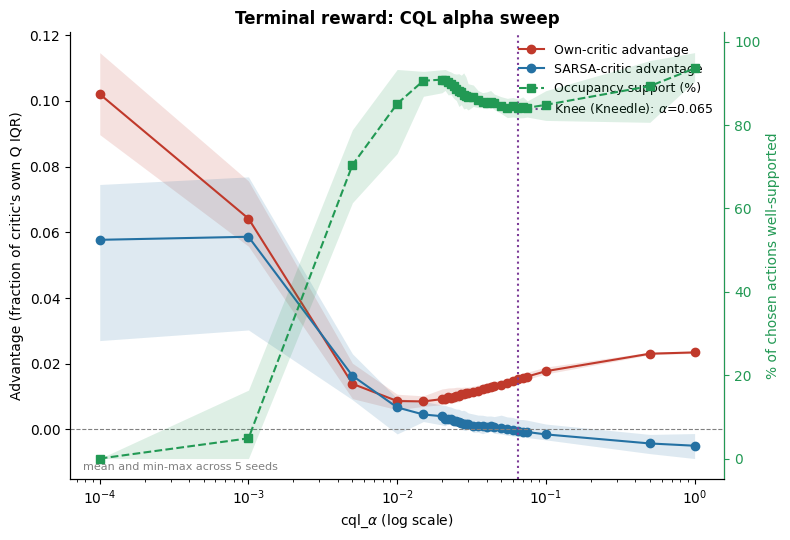

In [41]:
fig = eval_cql.plot_alpha_sweep(df_term, normalized=True, log_scale=True,
        save_path=os.path.join(cql_model_dir, "cql_alpha_sweep_terminal.png"))
fig = eval_cql.plot_combined_alpha_sweep(df_term, normalized=True, log_scale=True,
        title="Terminal reward: CQL alpha sweep",
        save_path=os.path.join(cql_model_dir, "cql_alpha_sweep_combined_terminal.png"))

,mean,std,n_seeds,n_seeds_positive,cv,worst_window_ratio,unstable
alpha,,,,,,,
0.0000,0.057680,0.019050,5,5,0.330263,1.016976,False
0.0001,0.057727,0.019040,5,5,0.329837,3.592125,True
0.0010,0.058659,0.018786,5,5,0.320259,8.765477,True
0.0050,0.016330,0.005805,5,5,0.355465,8.765477,True
0.0100,0.006692,0.004602,5,4,0.687638,8.765477,True
0.0150,0.004538,0.002560,5,5,0.564153,3.598314,True
0.0200,0.004016,0.002349,5,5,0.584750,1.666210,True
0.0210,0.003303,0.002387,5,5,0.722822,1.373957,True
0.0220,0.003183,0.002158,5,5,0.677927,1.261660,True


instability onset: 0.0001


max_ratio,1.25,1.50,2.00,3.00,5.00
window,,,,,
3,0.0001,0.0001,0.0001,0.0001,0.0010
4,0.0000,0.0000,0.0000,0.0000,0.0001
5,0.0000,0.0000,0.0000,0.0000,0.0000


Note: alpha=0 excluded from plot (log scale can't show it).
Saved to /home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/cql_with_logprobs/split_0/sepsis/combined_hourly_iv-vasoactive_inotropic_score/sarsa_stability_terminal.png


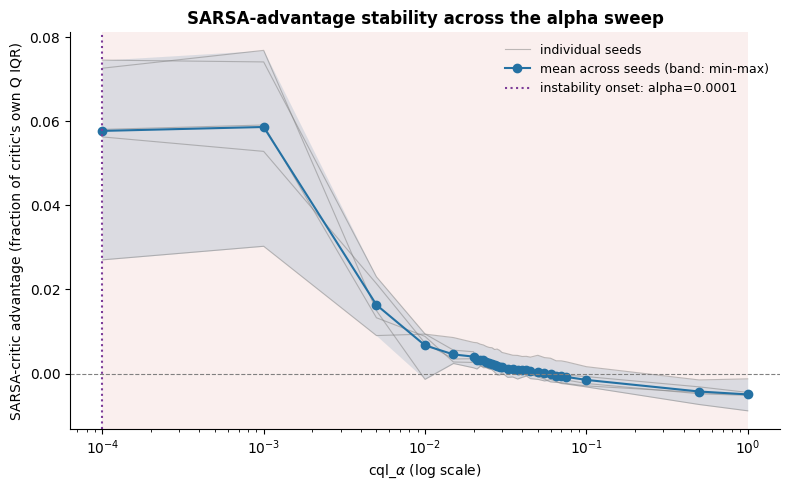

In [43]:
tab, onset = eval_cql.sarsa_stability(df_term, window=3, max_ratio=2.0)
display(tab)
print("instability onset:", onset)
display(eval_cql.stability_sensitivity(df_term))      # onset alpha across windows and thresholds

fig = eval_cql.plot_sarsa_stability(df_term, onset, normalized=True, log_scale=True,
        save_path=os.path.join(cql_model_dir, "sarsa_stability_terminal.png"))

In [44]:
final_alpha, sel_info = eval_cql.select_final_alpha(df_term, own_rule="any_seed", occupancy_margin=0.005)
display(sel_info)

alphas: 32
1. own-critic gate (any_seed): 32 pass; dropped []
2. SARSA stability gate (window=3, max_ratio=2.0): onset=0.0001; 1 survive both gates
3. occupancy: best survivor 0.00%, margin 0.50 points -> 1 tied: [0.0]
4. highest SARSA advantage among the tied: alpha=0 (SARSA adv 0.0577, occupancy 0.00%)


,own_adv_mean,own_adv_min,pass_own,pass_stability,sarsa_adv,occupancy,survivor,tied_occupancy,selected
alpha,,,,,,,,,
0.0000,0.106819,0.094150,True,True,0.057680,0.000000,True,True,True
0.0001,0.102085,0.089759,True,False,0.057727,0.000000,False,False,False
0.0010,0.064190,0.055765,True,False,0.058659,0.048505,False,False,False
0.0050,0.013886,0.009368,True,False,0.016330,0.704384,False,False,False
0.0100,0.008632,0.005989,True,False,0.006692,0.851287,False,False,False
0.0150,0.008517,0.007004,True,False,0.004538,0.906424,False,False,False
0.0200,0.009216,0.007525,True,False,0.004016,0.909174,False,False,False
0.0210,0.009367,0.007657,True,False,0.003303,0.907442,False,False,False
0.0220,0.009788,0.007897,True,False,0.003183,0.903783,False,False,False


In [45]:
sig = lambda s: dict(D.reward_signature(s.runs()[0]))
a, b = sig(term_study), sig(sarsa_term_study)
print({k: (a.get(k), b.get(k)) for k in sorted(set(a) | set(b)) if a.get(k) != b.get(k)})

{'make_rewards_positive': (None, 'False')}


In [46]:
sigs = lambda s: {D.reward_signature(r) for r in s.runs()}
print(len(sigs(term_study)), len(sigs(sarsa_term_study)), sigs(term_study) == sigs(sarsa_term_study))
print({r.get("reward_type") for r in term_study.runs()}, {r.get("reward_type") for r in sarsa_term_study.runs()})

1 1 False
{'terminal'} {'terminal'}


## Action distributions

Saved to /home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/cql_with_logprobs/split_0/sepsis/combined_hourly_iv-vasoactive_inotropic_score/dose_histogram_fluid_terminal.png
Saved to /home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/cql_with_logprobs/split_0/sepsis/combined_hourly_iv-vasoactive_inotropic_score/fluid_at_clinician_zero_terminal.png
Saved to /home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/cql_with_logprobs/split_0/sepsis/combined_hourly_iv-vasoactive_inotropic_score/dose_histogram_vaso_terminal.png
Saved to /home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/cql_with_logprobs/split_0/sepsis/combined_hourly_iv-vasoactive_inotropic_score/vaso_at_clinician_zero_terminal.png


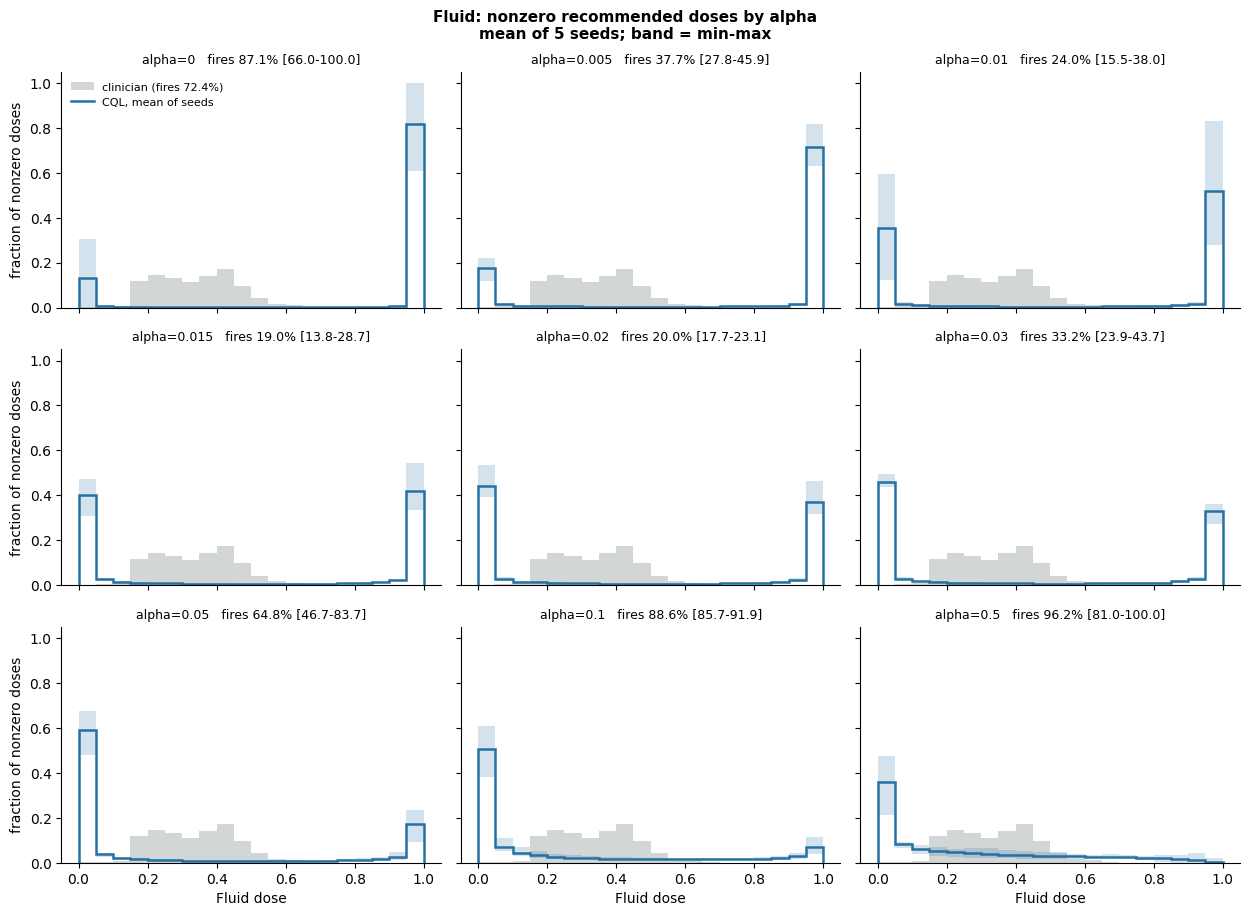

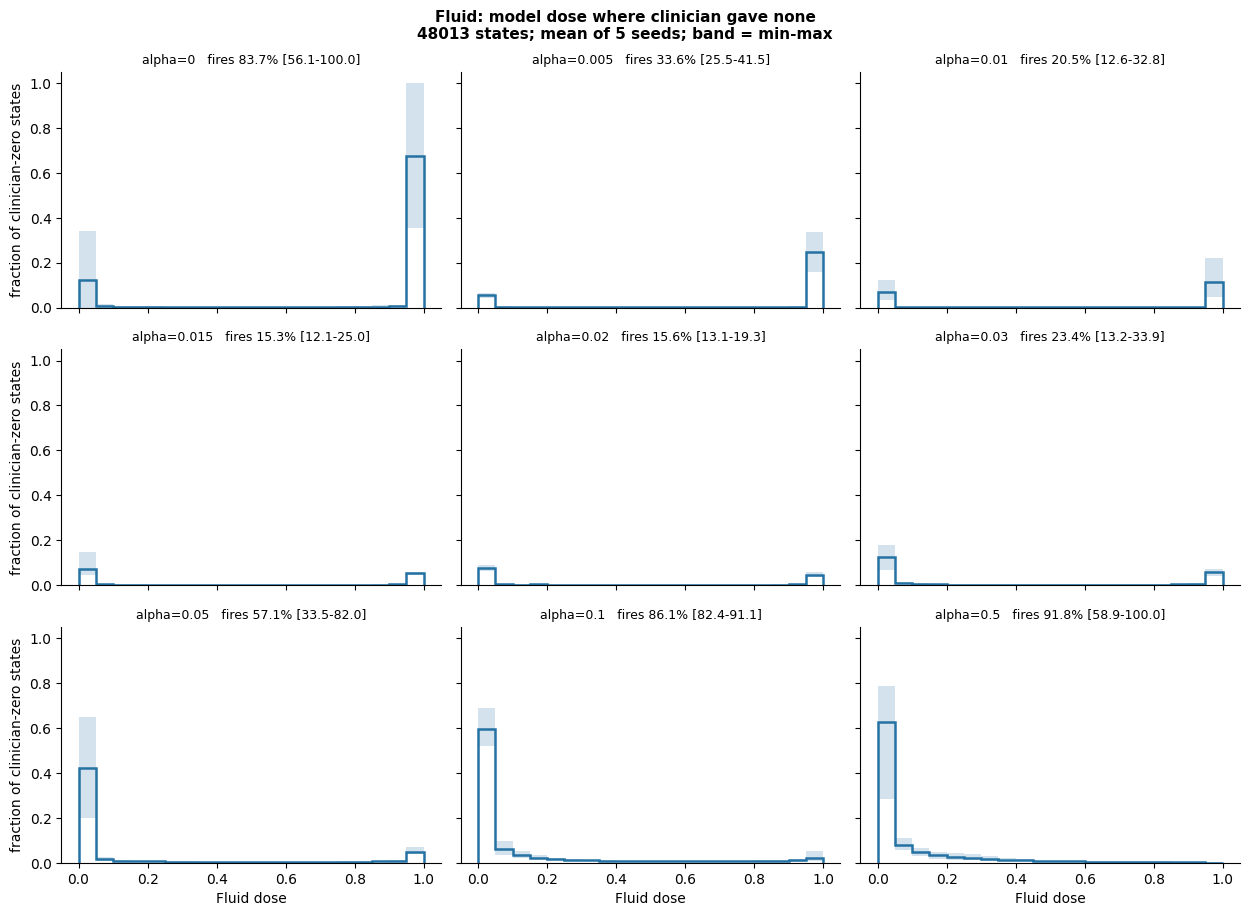

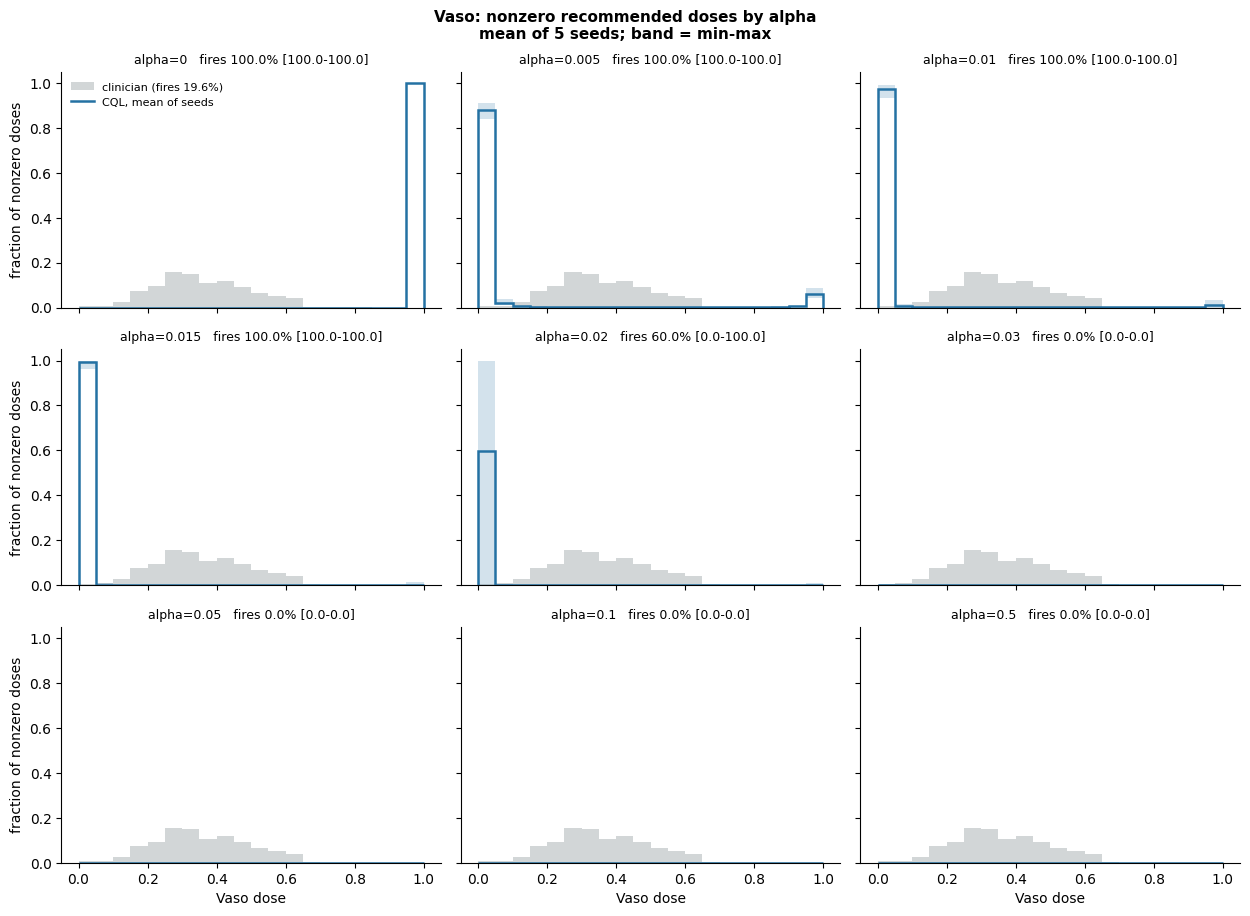

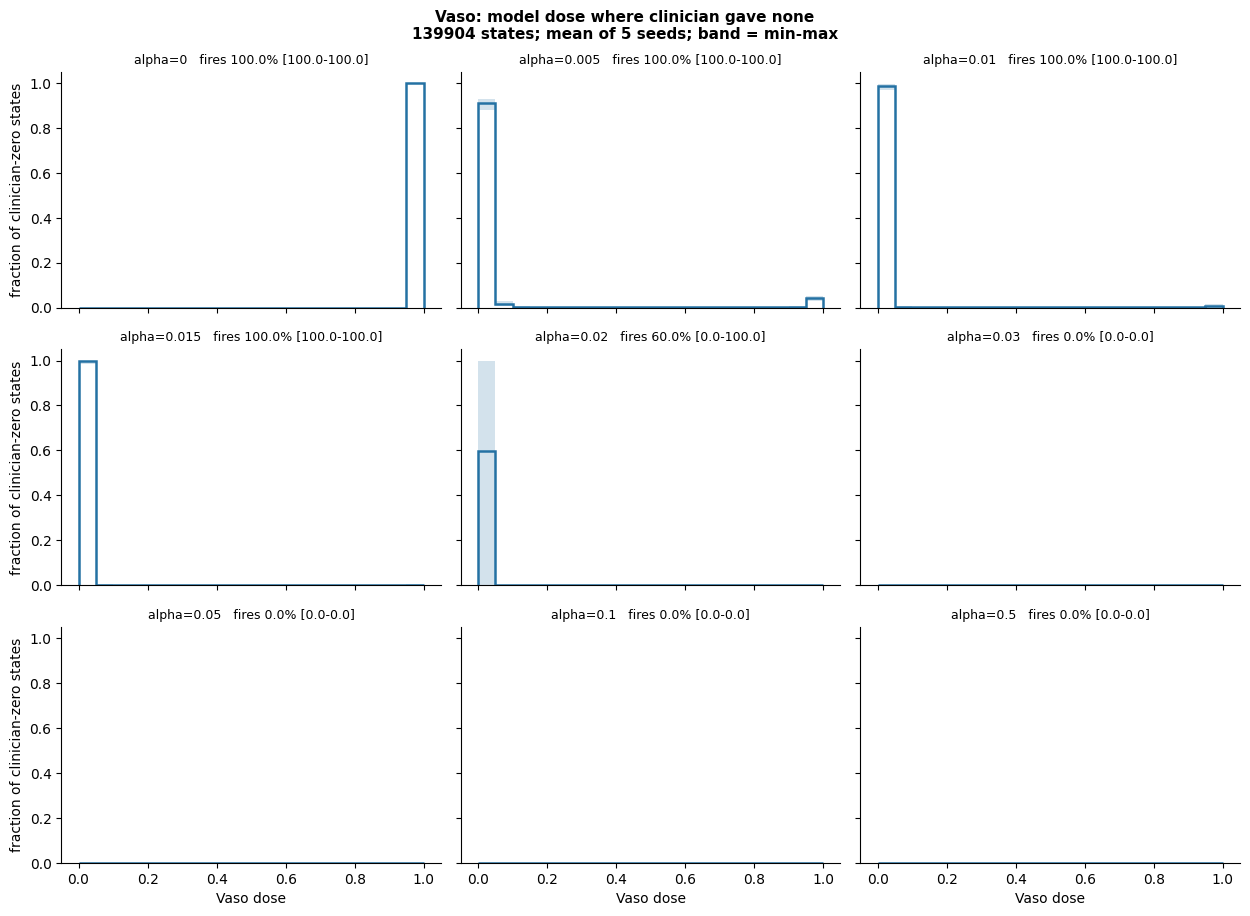

In [47]:
import src.rl.dose_histogram_by_alpha as dose_hist

actions_term, clin_val = dose_hist.collect_actions(cql_term_models, store, split="val")   # once; reused by all plots

show = [0, 0.005, 0.01, 0.015, 0.02, 0.03, 0.05, 0.1, 0.5]
for dim, name in [(0, "Fluid"), (1, "Vaso")]:
    dose_hist.plot_dose_histograms(actions_term, clin_val, dim=dim, dim_name=name, alphas_to_show=show,
        save_path=os.path.join(cql_model_dir, f"dose_histogram_{name.lower()}_terminal.png"))
    dose_hist.plot_dose_histograms_at_clinician_zero(actions_term, clin_val, dim=dim, dim_name=name, alphas_to_show=show,
        save_path=os.path.join(cql_model_dir, f"{name.lower()}_at_clinician_zero_terminal.png"))